#### Trabajo Práctico · 2.er Cuatrimestre 2026

### METODOS PREDICTIVOS PARA LA GESTION

#### Tecnicatura Universitaria en Gestión y Análisis de Datos - FCE UBA

--------------------------------------------------------------------------


### 0. DESCRIPCIÓN Y FUENTE DEL DATASET

Para el desarrollo del trabajo se seleccionó el dataset Online News Popularity, disponible en el UCI Machine Learning Repository.

La base contiene información sobre artículos publicados por Mashable durante un período de dos años. Cada registro representa un artículo y contiene distintas características asociadas a su contenido y publicación, como la cantidad de palabras del título y del artículo, número de imágenes y videos, cantidad de enlaces, palabras clave, temática, día de publicación y diferentes indicadores relacionados con la subjetividad y el sentimiento del contenido.

El dataset cuenta con 39.797 observaciones y 58 variables predictoras. Además, incluye variables no predictivas y la variable objetivo shares, que representa la cantidad de veces que cada artículo fue compartido en redes sociales.

El objetivo del análisis será estudiar la relación entre las características de los artículos y su popularidad, buscando predecir la cantidad de veces que un artículo será compartido. Debido a que la variable objetivo shares es numérica, el problema será abordado mediante técnicas de regresión.

Fuente: UCI Machine Learning Repository — Online News Popularity.
Autores: Kelwin Fernandes, Pedro Vinagre, Paulo Cortez y Pedro Sernadela.

--------------------------------------------------------------------------

## 1. CARGA Y EXPLORACIÓN INICIAL DEL DATASET

En esta sección se realiza la carga de la base y una primera inspección de su estructura, sin aplicar todavía transformaciones sobre los datos.


### 1.1 Carga de librerías y del dataset


In [1]:
# Importamos la función fetch_ucirepo de la librería ucimlrepo.
# Esta función permite descargar datasets directamente desde
# el repositorio UCI Machine Learning Repository (https://archive.ics.uci.edu/).
%pip install ucimlrepo
from ucimlrepo import fetch_ucirepo
import pandas as pd

In [2]:
# Descargamos el dataset "Online News Popularity".
# El parámetro id=332 identifica de manera única a este dataset dentro del repositorio UCI.
online_news_popularity = fetch_ucirepo(id=332)

# Separamos las variables predictoras (X) de la variable objetivo (y).
# X2 contiene las características de los artículos que utilizaremos como predictoras.
X2 = online_news_popularity.data.features

# y2 contiene la variable objetivo "shares":
# cantidad de veces que un artículo fue compartido.
y2 = online_news_popularity.data.targets

# Mostramos los metadatos generales del dataset.
print(online_news_popularity.metadata)

# Mostramos la información provista por UCI sobre cada variable.
print(online_news_popularity.variables)


{'uci_id': 332, 'name': 'Online News Popularity', 'repository_url': 'https://archive.ics.uci.edu/dataset/332/online+news+popularity', 'data_url': 'https://archive.ics.uci.edu/static/public/332/data.csv', 'abstract': 'This dataset summarizes a heterogeneous set of features about articles published by Mashable in a period of two years. The goal is to predict the number of shares in social networks (popularity).', 'area': 'Business', 'tasks': ['Classification', 'Regression'], 'characteristics': ['Multivariate'], 'num_instances': 39797, 'num_features': 58, 'feature_types': ['Integer', 'Real'], 'demographics': [], 'target_col': [' shares'], 'index_col': ['url'], 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2015, 'last_updated': 'Thu Feb 15 2024', 'dataset_doi': '10.24432/C5NS3V', 'creators': ['Kelwin Fernandes', 'Pedro Vinagre', 'Paulo Cortez', 'Pedro Sernadela'], 'intro_paper': {'ID': 390, 'type': 'NATIVE', 'title': 'A Proactive Intelligent Decisio

### 1.2 Dimensiones e identificación de la variable objetivo


In [3]:
# Mostramos los nombres de las variables predictoras
print("Variables predictoras:")
print(X2.columns)

# Mostramos el nombre de la variable objetivo
print("\nVariable objetivo:")
print(y2.columns)

# Mostramos las dimensiones de ambos DataFrames
print("\nDimensiones:")
print("X2:", X2.shape)
print("y2:", y2.shape)

Variables predictoras:
Index([' n_tokens_title', ' n_tokens_content', ' n_unique_tokens',
       ' n_non_stop_words', ' n_non_stop_unique_tokens', ' num_hrefs',
       ' num_self_hrefs', ' num_imgs', ' num_videos', ' average_token_length',
       ' num_keywords', ' data_channel_is_lifestyle',
       ' data_channel_is_entertainment', ' data_channel_is_bus',
       ' data_channel_is_socmed', ' data_channel_is_tech',
       ' data_channel_is_world', ' kw_min_min', ' kw_max_min', ' kw_avg_min',
       ' kw_min_max', ' kw_max_max', ' kw_avg_max', ' kw_min_avg',
       ' kw_max_avg', ' kw_avg_avg', ' self_reference_min_shares',
       ' self_reference_max_shares', ' self_reference_avg_sharess',
       ' weekday_is_monday', ' weekday_is_tuesday', ' weekday_is_wednesday',
       ' weekday_is_thursday', ' weekday_is_friday', ' weekday_is_saturday',
       ' weekday_is_sunday', ' is_weekend', ' LDA_00', ' LDA_01', ' LDA_02',
       ' LDA_03', ' LDA_04', ' global_subjectivity',
       ' global_se

### 1.3 Normalización de los nombres de las variables


In [4]:
# Los nombres de las variables poseen espacios a los costados

# Limpiamos los nombres de las variables predictoras
X2.columns = X2.columns.str.strip()

# Limpiamos el nombre de la variable objetivo
y2.columns = y2.columns.str.strip()

### 1.4 Construcción del DataFrame completo


In [5]:
# Unimos las variables predictoras (X2) con la variable objetivo (y2)
# para disponer de un DataFrame completo para el análisis exploratorio.
df = pd.concat([X2, y2], axis=1)

### 1.5 Inspección inicial de la estructura


In [6]:
# Dimensiones del DataFrame completo: filas y columnas.
df.shape


(39644, 59)

In [7]:
# Estructura general: nombres de columnas, tipos de datos y valores no nulos.
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39644 entries, 0 to 39643
Data columns (total 59 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   n_tokens_title                 39644 non-null  float64
 1   n_tokens_content               39644 non-null  float64
 2   n_unique_tokens                39644 non-null  float64
 3   n_non_stop_words               39644 non-null  float64
 4   n_non_stop_unique_tokens       39644 non-null  float64
 5   num_hrefs                      39644 non-null  float64
 6   num_self_hrefs                 39644 non-null  float64
 7   num_imgs                       39644 non-null  float64
 8   num_videos                     39644 non-null  float64
 9   average_token_length           39644 non-null  float64
 10  num_keywords                   39644 non-null  float64
 11  data_channel_is_lifestyle      39644 non-null  float64
 12  data_channel_is_entertainment  39644 non-null 

### 1.6 Inventario y tipología de variables


Se visualizarán los primeros 10 registros para obtener un panorama general de los campos (las columnas que no caben, se visualizarán por fuera de este informe, pero serán descritas y mostradas por separado posteriormente).

In [8]:
df.head(10)

,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens,num_hrefs,num_self_hrefs,num_imgs,num_videos,average_token_length,...,min_positive_polarity,max_positive_polarity,avg_negative_polarity,min_negative_polarity,max_negative_polarity,title_subjectivity,title_sentiment_polarity,abs_title_subjectivity,abs_title_sentiment_polarity,shares
0,12.0,219.0,0.663594,1.0,0.815385,4.0,2.0,1.0,0.0,4.680365,...,0.100000,0.7,-0.350000,-0.600,-0.200000,0.500000,-0.187500,0.000000,0.187500,593
1,9.0,255.0,0.604743,1.0,0.791946,3.0,1.0,1.0,0.0,4.913725,...,0.033333,0.7,-0.118750,-0.125,-0.100000,0.000000,0.000000,0.500000,0.000000,711
2,9.0,211.0,0.575130,1.0,0.663866,3.0,1.0,1.0,0.0,4.393365,...,0.100000,1.0,-0.466667,-0.800,-0.133333,0.000000,0.000000,0.500000,0.000000,1500
3,9.0,531.0,0.503788,1.0,0.665635,9.0,0.0,1.0,0.0,4.404896,...,0.136364,0.8,-0.369697,-0.600,-0.166667,0.000000,0.000000,0.500000,0.000000,1200
4,13.0,1072.0,0.415646,1.0,0.540890,19.0,19.0,20.0,0.0,4.682836,...,0.033333,1.0,-0.220192,-0.500,-0.050000,0.454545,0.136364,0.045455,0.136364,505
5,10.0,370.0,0.559889,1.0,0.698198,2.0,2.0,0.0,0.0,4.359459,...,0.136364,0.6,-0.195000,-0.400,-0.100000,0.642857,0.214286,0.142857,0.214286,855
6,8.0,960.0,0.418163,1.0,0.549834,21.0,20.0,20.0,0.0,4.654167,...,0.100000,1.0,-0.224479,-0.500,-0.050000,0.000000,0.000000,0.500000,0.000000,556
7,12.0,989.0,0.433574,1.0,0.572108,20.0,20.0,20.0,0.0,4.617796,...,0.100000,1.0,-0.242778,-0.500,-0.050000,1.000000,0.500000,0.500000,0.500000,891
8,11.0,97.0,0.670103,1.0,0.836735,2.0,0.0,0.0,0.0,4.855670,...,0.400000,0.8,-0.125000,-0.125,-0.125000,0.125000,0.000000,0.375000,0.000000,3600
9,10.0,231.0,0.636364,1.0,0.797101,4.0,1.0,1.0,1.0,5.090909,...,0.100000,0.5,-0.238095,-0.500,-0.100000,0.000000,0.000000,0.500000,0.000000,710


Se clasifican las variables a continuación en distintos grupos conceptuales, para su mejor desarrollo, a los fines de facilitar la definición respecto al significado de cada una.

In [9]:
#Agrupamiento de los nombres de las variables en listas asociadas correspondientemente a sus grupos conceptuales bajo los cuales se clasificaron dichas variables aleatorias.
cols_estr_art = [
    "n_tokens_title",
    "n_tokens_content",
    "n_unique_tokens",
    "n_non_stop_words",
    "n_non_stop_unique_tokens",
    "average_token_length",
    "num_keywords"
]

cols_enlaces_multimedia = [
    "num_hrefs",
    "num_self_hrefs",
    "num_imgs",
    "num_videos"
]

cols_canal_tematico = [
    "data_channel_is_lifestyle",
    "data_channel_is_entertainment",
    "data_channel_is_bus",
    "data_channel_is_socmed",
    "data_channel_is_tech",
    "data_channel_is_world"
]

cols_keywords = [
    "kw_min_min",
    "kw_max_min",
    "kw_avg_min",
    "kw_min_max",
    "kw_max_max",
    "kw_avg_max",
    "kw_min_avg",
    "kw_max_avg",
    "kw_avg_avg"
]

cols_referencias = [
    "self_reference_min_shares",
    "self_reference_max_shares",
    "self_reference_avg_sharess"
]

cols_dia_publicacion = [
    "weekday_is_monday",
    "weekday_is_tuesday",
    "weekday_is_wednesday",
    "weekday_is_thursday",
    "weekday_is_friday",
    "weekday_is_saturday",
    "weekday_is_sunday",
    "is_weekend"
]

cols_lda = [
    "LDA_00",
    "LDA_01",
    "LDA_02",
    "LDA_03",
    "LDA_04"
]

cols_sentimiento_subjetividad = [
    "global_subjectivity",
    "global_sentiment_polarity",
    "global_rate_positive_words",
    "global_rate_negative_words",
    "rate_positive_words",
    "rate_negative_words",
    "avg_positive_polarity",
    "min_positive_polarity",
    "max_positive_polarity",
    "avg_negative_polarity",
    "min_negative_polarity",
    "max_negative_polarity",
    "title_subjectivity",
    "title_sentiment_polarity",
    "abs_title_subjectivity",
    "abs_title_sentiment_polarity"
]

cols_no_predictivas = [
    "url",
    "timedelta"
]

col_objetivo = [
    "shares"
]

**Estructura del artículo**

In [10]:
df.loc[:,cols_estr_art] #Se seleccionan los atributos correspondientes a variables clasificadas dentro del conjunto de Estructura del Artículo.

,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens,average_token_length,num_keywords
0,12.0,219.0,0.663594,1.0,0.815385,4.680365,5.0
1,9.0,255.0,0.604743,1.0,0.791946,4.913725,4.0
2,9.0,211.0,0.575130,1.0,0.663866,4.393365,6.0
3,9.0,531.0,0.503788,1.0,0.665635,4.404896,7.0
4,13.0,1072.0,0.415646,1.0,0.540890,4.682836,7.0
...,...,...,...,...,...,...,...
39639,11.0,346.0,0.529052,1.0,0.684783,4.523121,8.0
39640,12.0,328.0,0.696296,1.0,0.885057,4.405488,7.0
39641,10.0,442.0,0.516355,1.0,0.644128,5.076923,8.0
39642,6.0,682.0,0.539493,1.0,0.692661,4.975073,5.0


Variables de estructura del artículo:

* n_tokens_title: cantidad de palabras del título
* n_tokens_content: cantidad de palabras del cuerpo del artículo (qué tan largo es).
* n_unique_tokens: proporción de palabras distintas dentro del artículo con respecto al número de palabras totales. Si se repiten m palabras de las n palabras totales de un artículo, entonces:

  $$

  \text{n\_unique\_tokens} = \frac{m}{n} \forall m<n \wedge m,n\in \mathbb{N} \implies \text{n\_unique\_tokens}\in [0;1] \in \mathbb{Z}
  
  $$
  
  Téngase en cuenta que al considerar el conjunto de los naturales para m y n, se garantiza evitar la división por cero, la cual tampoco tendría sentido en el contexto de este análisis debido a la propia naturaleza comunicativa de un artículo redactado en lenguas germánicas.
  Resulta de importancia aclarar, con respecto a esta variable, que siempre está comprendida en un rango entre 0 y 1 como recién se especificó, permitiendo una comparación entre todas las observaciones del espectro de valores que adopta en la muestra dada y evitando una correlación innecesaria entre la variable n_tokens_content y una variable que sería m por sí sola (podría llamarse m_non_stop_tokens), justamente debido a que, a mayor número de palabras totales, podría existir una tendencia a tener mayor número de palabras distintas, lo cual no es posible determinar a priori con base a esto por sí solo, como consecuencia factores a considerar tales como adaptación del léxico empleado en la redacción, incluyendo la aleatoriedad misma, por lo que esta correlación se encuentra sujeta a un posible "enmascaramiento" por superposición de causas ajenas al propio n_tokens_content.
* n_non_stop_words: stop words son palabras muy frecuentes pero que aportan poca información para el análisis del texto, las cuales son conectores y preposiciones como "el", "la", "de", "y", entre otras. Por lo tanto, n_non_stop_words es el número de palabras que **no** son stop words.
* n_non_stop_unique_tokens: dadas las explicaciones anteriores, esta variable es la proporción de palabras que no son stop words y que, además, son únicas. Aplíquese análogamente los conceptos anteriormente desarrollados a la comprensión de la descripción realizada en torno a esta variable.
* average_token_length: longitud promedio de las palabras del artículo. Esto es:
$$
\sum_{i=1}^{L}{\frac{\text{Número de caracteres}_i}{\text{n\_tokens\_content}}}
$$
Siendo i el índice para indicar "la i-ésima palabra" dentro del artículo considerado de un total de L palabras.
* num_keywords: cantidad de palabras clave asociadas al artículo.


Todas estas variables son cuantitativas.

In [11]:
df.loc[:,cols_enlaces_multimedia] #atributos de enlaces multimedia

,num_hrefs,num_self_hrefs,num_imgs,num_videos
0,4.0,2.0,1.0,0.0
1,3.0,1.0,1.0,0.0
2,3.0,1.0,1.0,0.0
3,9.0,0.0,1.0,0.0
4,19.0,19.0,20.0,0.0
...,...,...,...,...
39639,9.0,7.0,1.0,1.0
39640,9.0,7.0,3.0,48.0
39641,24.0,1.0,12.0,1.0
39642,10.0,1.0,1.0,0.0


**Variables de enlaces multimedia**
* num_hrefs: número total de links del artículo.
* num_self_hrefs: cantidad de links internos que apuntan a otros artículos de Mashable (medio que publicó los artículos del dataset).
* num_imgs: número de imágenes
* num_videos: cantidad de videos

Nuevamente, variables cuantitativas.

In [12]:
df.loc[:,cols_canal_tematico] #Atributos canal temático.

,data_channel_is_lifestyle,data_channel_is_entertainment,data_channel_is_bus,data_channel_is_socmed,data_channel_is_tech,data_channel_is_world
0,0.0,1.0,0.0,0.0,0.0,0.0
1,0.0,0.0,1.0,0.0,0.0,0.0
2,0.0,0.0,1.0,0.0,0.0,0.0
3,0.0,1.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...
39639,0.0,0.0,0.0,0.0,1.0,0.0
39640,0.0,0.0,0.0,1.0,0.0,0.0
39641,0.0,0.0,0.0,0.0,0.0,0.0
39642,0.0,0.0,0.0,0.0,0.0,1.0


Temática o canal del artículo:
* data_channel_is_lifestyle: estilo de vida (como en TV, el canal Discovery Home & Health).
* data_channel_is_entertainment: entretenimiento
* data_channel_is_bus: negocios
* data_channel_is_socmed: redes sociales.
* data_channel_is_tech: tecnología
* data_channel_is_world: global

Estas son variables cualitativas que corresponden a una numerización y cuyos atributos "dummy", columnas binarias por cada uno de los valores del atributo original (temática o canal) ya fueron creadas desde la fuente, es decir, estas son variables dummy provenientes del dataframe original y ahorran otro paso.

In [13]:
df.loc[:,cols_keywords] #Atributos asociados a palabras clave

,kw_min_min,kw_max_min,kw_avg_min,kw_min_max,kw_max_max,kw_avg_max,kw_min_avg,kw_max_avg,kw_avg_avg
0,0.0,0.0,0.000,0.0,0.0,0.000000,0.000000,0.000000,0.000000
1,0.0,0.0,0.000,0.0,0.0,0.000000,0.000000,0.000000,0.000000
2,0.0,0.0,0.000,0.0,0.0,0.000000,0.000000,0.000000,0.000000
3,0.0,0.0,0.000,0.0,0.0,0.000000,0.000000,0.000000,0.000000
4,0.0,0.0,0.000,0.0,0.0,0.000000,0.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...
39639,-1.0,671.0,173.125,26900.0,843300.0,374962.500000,2514.742857,4004.342857,3031.115764
39640,-1.0,616.0,184.000,6500.0,843300.0,192985.714286,1664.267857,5470.168651,3411.660830
39641,-1.0,691.0,168.250,6200.0,843300.0,295850.000000,1753.882353,6880.687034,4206.439195
39642,-1.0,0.0,-1.000,0.0,843300.0,254600.000000,0.000000,3384.316871,1777.895883


Variables asociadas a estimadores muestrales de palabras clave:
Describen qué tan populares son las palabras clave asociadas con el artículo, usando como referencia las veces que otros artículos asociados a esas keywords fueron compartidos.
Es como una forma de medir popularidad por cantidad de veces que se compartieron otros artículos asociados, siendo el vínculo entre ambos establecido a través de las keywords. Es conceptualmente análogo a tener un Hashtag tendencia en una red social, o un trending topic, sólo que asociado a palabras clave.

* kw_min_min: El mínimo de shares asociado a las keywords, tomando el mínimo de cada keyword.
* kw_max_min: El máximo de esos mínimos.
* kw_avg_min: El promedio de esos mínimos.
* kw_min_min: El mínimo de shares asociado a las keywords, tomando el mínimo de cada keyword.
* kw_max_min: El máximo de esos mínimos.
* kw_avg_min: El promedio de esos mínimos.

Aplíquese análogamente a los máximos y promedios de shares históricos de las palabras clave, que están contempladas en las demás variables exhibidas en el dataframe anterior.

Variables cuantitativas.



In [14]:
df.loc[:,cols_dia_publicacion]

,weekday_is_monday,weekday_is_tuesday,weekday_is_wednesday,weekday_is_thursday,weekday_is_friday,weekday_is_saturday,weekday_is_sunday,is_weekend
0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...
39639,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
39640,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
39641,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
39642,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


**Día de la publicación**:

Son variables dummy, una por cada día de la semana, otra numerización ya realizada desde el dataframe original.

Variable cualitativa ya numerizada.
Is weekend indica si es fin de semana o no. Aquí es menester evaluar si no hay correlación entre las 7 variables de día de semana y la octava de fin de semana.

In [15]:
df.loc[:,cols_lda]

,LDA_00,LDA_01,LDA_02,LDA_03,LDA_04
0,0.500331,0.378279,0.040005,0.041263,0.040123
1,0.799756,0.050047,0.050096,0.050101,0.050001
2,0.217792,0.033334,0.033351,0.033334,0.682188
3,0.028573,0.419300,0.494651,0.028905,0.028572
4,0.028633,0.028794,0.028575,0.028572,0.885427
...,...,...,...,...,...
39639,0.025038,0.025001,0.151701,0.025000,0.773260
39640,0.029349,0.028575,0.231866,0.681635,0.028575
39641,0.159004,0.025025,0.025207,0.643794,0.146970
39642,0.040004,0.040003,0.839987,0.040002,0.040004


**LDA: Latent Dirichlet Allocation**:

Es una técnica mediante la cual se infiere de qué temáticas o tópicos hace referencia o comunica un documento en base a las palabras que contiene, lo cual arroja valores donde cada artículo tiene una asociación comprendida entre 0 y 1 para cada temática. Anteriormente se describieron 6 temáticas, pero en las columnas de LDA sólo hay 5. Esto es lógico porque la sumatoria de las puntuaciones de las 6 temáticas debe resultar igaul a 1 como resultado total. Si se utilizaran las 6 variables, claramente la sexta siempre sería linealmente dependiente de las otras 5 (n-1 grados de libertad).

El nivel de asociación de un artículo con una temática no sería en sí mismo cualitativo porque se está haciendo la estimación de un parámetro, por lo que podría ser cuantitativo, y aun así estas variables podrían introducir un componente de aleatoriedad adicional, aunque permiten evaluar qué tan amplio es el abanico de temas que abarca a un artículo, lo cual podría favorecer el abordaje de un público más heterogéneo y, consecuentemente, favorecer su popularidad. Es relevante para el análisis, en vista de lo cual, debe tenerse en consideración siempre y cuando no produzca inconvenientes para la regresión.

In [16]:
df.loc[:,cols_sentimiento_subjetividad]

,global_subjectivity,global_sentiment_polarity,global_rate_positive_words,global_rate_negative_words,rate_positive_words,rate_negative_words,avg_positive_polarity,min_positive_polarity,max_positive_polarity,avg_negative_polarity,min_negative_polarity,max_negative_polarity,title_subjectivity,title_sentiment_polarity,abs_title_subjectivity,abs_title_sentiment_polarity
0,0.521617,0.092562,0.045662,0.013699,0.769231,0.230769,0.378636,0.100000,0.70,-0.350000,-0.600,-0.200000,0.500000,-0.187500,0.000000,0.187500
1,0.341246,0.148948,0.043137,0.015686,0.733333,0.266667,0.286915,0.033333,0.70,-0.118750,-0.125,-0.100000,0.000000,0.000000,0.500000,0.000000
2,0.702222,0.323333,0.056872,0.009479,0.857143,0.142857,0.495833,0.100000,1.00,-0.466667,-0.800,-0.133333,0.000000,0.000000,0.500000,0.000000
3,0.429850,0.100705,0.041431,0.020716,0.666667,0.333333,0.385965,0.136364,0.80,-0.369697,-0.600,-0.166667,0.000000,0.000000,0.500000,0.000000
4,0.513502,0.281003,0.074627,0.012127,0.860215,0.139785,0.411127,0.033333,1.00,-0.220192,-0.500,-0.050000,0.454545,0.136364,0.045455,0.136364
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
39639,0.482679,0.141964,0.037572,0.014451,0.722222,0.277778,0.333791,0.100000,0.75,-0.260000,-0.500,-0.125000,0.100000,0.000000,0.400000,0.000000
39640,0.564374,0.194249,0.039634,0.009146,0.812500,0.187500,0.374825,0.136364,0.70,-0.211111,-0.400,-0.100000,0.300000,1.000000,0.200000,1.000000
39641,0.510296,0.024609,0.033937,0.024887,0.576923,0.423077,0.307273,0.136364,0.50,-0.356439,-0.800,-0.166667,0.454545,0.136364,0.045455,0.136364
39642,0.358578,-0.008066,0.020528,0.023460,0.466667,0.533333,0.236851,0.062500,0.50,-0.205246,-0.500,-0.012500,0.000000,0.000000,0.500000,0.000000


Variables de sentimiento y polaridad:
Son cualitativas y describen hacia qué sentimiento tiende el artículo, proporción de palabras positivas y negativas (prestar atención a que ambas suman 1 en el caso del análisis global, pero en el no global se excluyen las no neutrales, lo que evita multicolinealidad) y polaridad (hacia qué sentimiento tienden) las palabras positivas y negativas cuantificando su intensidad.
Aquí tenemos variables cuantitativas.

### 1.7 Análisis de escalas y rangos

Normalización analizada previamente. La estandarización se evaluará en el análisis de outliers para variables cuantitativas.


## 2. LIMPIEZA Y PREPROCESAMIENTO

### 2.1 Valores faltantes

### Identificación de campos con valores faltantes:

In [17]:
df.isna().sum().sort_values(ascending=False)

,0
n_tokens_title,0
n_tokens_content,0
n_unique_tokens,0
n_non_stop_words,0
n_non_stop_unique_tokens,0
num_hrefs,0
num_self_hrefs,0
num_imgs,0
num_videos,0
average_token_length,0


No se encuentran presentes valores faltantes en ningún campo, por lo que no es necesario realizar imputación de valores de momento. Los demás tratamientos serán evaluados en el análisis de outliers, cuya sección correspondiente se desarrolla en apartado homónimo posterior.

### 2.2 Registros duplicados

In [18]:
print(f"Suma de registros duplicados: {df.duplicated().sum()}") #suma de registros duplicados


Suma de registros duplicados: 0


### 2.3 Inconsistencias

In [19]:
#Se aplicará a variables cualitativas
df[cols_canal_tematico].isin([0, 1]).all().all() #Se verifica que las columnas de canal temático sean de 0 y 1, no pueden ser no binarias porque son columnas dummy.

np.True_

La salida anterior arroja como resultado el valor verdadero, por lo que todas las columnas de canal temático respetan la regla de numerización.

In [20]:
cols_dia_publicacion = [
    "weekday_is_monday",
    "weekday_is_tuesday",
    "weekday_is_wednesday",
    "weekday_is_thursday",
    "weekday_is_friday",
    "weekday_is_saturday",
    "weekday_is_sunday"
]
df[cols_dia_publicacion].sum(axis=1).value_counts()

,count
1.0,39644


Se verifica que cada artículo se corresponda con un día de la semana, dada la imposibilidad física temporal de registrar un mismo suceso de creación de un documento en dos fechas distintas, teniendo en consideración que una modificación o una hipotética eliminación, modificación y creación sucesiva posterior son escenarios no contemplados dentro del marco de análisis.
La suma debe ser igual al número de registros (39644) para el valor 1 y no debe figurar ningún otro valor.

El dataframe también es consistente en días de publicación.

In [21]:
#Verificación de sumas de LDA = 1 (explicado en descripción de campos).
import numpy as np #Se imoprta numpy para operaciones algebraicas y redondeos en este caso.
suma_lda = df[cols_lda].sum(axis=1) #suma de los LDA a lo largo de cada registro.
resultado = pd.Series(np.isclose(suma_lda, 1)) #Se observan cuántos cumplen con la suma de LDA = 1, con tolerancia de redondeo.
resultado.value_counts() #Conteo de los resultados

,count
True,39643
False,1


In [22]:
df.loc[~resultado, cols_lda] #Debido a la aparción de un resultado inconsistente con esta regla, se visualizará el mismo.

,LDA_00,LDA_01,LDA_02,LDA_03,LDA_04
31037,0.0,0.0,0.0,0.0,0.0


In [23]:
#Selección del registro completo para mayor detalle.
df.loc[~resultado, :]

,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens,num_hrefs,num_self_hrefs,num_imgs,num_videos,average_token_length,...,min_positive_polarity,max_positive_polarity,avg_negative_polarity,min_negative_polarity,max_negative_polarity,title_subjectivity,title_sentiment_polarity,abs_title_subjectivity,abs_title_sentiment_polarity,shares
31037,9.0,1570.0,701.0,1042.0,650.0,11.0,10.0,51.0,0.0,4.696178,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5900


El resultado anterior es de un artículo de entretenimiento.
Dicho registro identificado, contextualizado dentro de la categoría correspondiente al tópico señalado, con un número de 1570 palabras, 701 palabras distintas y 650 palabras non-stop, resulta particularmente relevante en carácter de objeto de estudio, cuyo suceso asociado con causa a investigar es la evidente ausencia de datos asociados a alguna inferencia con respecto a la temática de este artículo en el campo correspondiente.
Resulta necesario evaluar el impacto que tiene este valor inconsistente en el conjunto. Ya de por sí representa un ínfimo porcentaje con respecto al total por ser un único registro con inconsistencias.
Primero se examinará con mayor detenimiento en pos de inferir causa posible, sea simple o compuesta, a los fines de los cual, su evaluación es posible, haciendo uso convenientemente de las columnas que faltan en la visualización anterior del df.

In [24]:
df.loc[~resultado,cols_sentimiento_subjetividad]

,global_subjectivity,global_sentiment_polarity,global_rate_positive_words,global_rate_negative_words,rate_positive_words,rate_negative_words,avg_positive_polarity,min_positive_polarity,max_positive_polarity,avg_negative_polarity,min_negative_polarity,max_negative_polarity,title_subjectivity,title_sentiment_polarity,abs_title_subjectivity,abs_title_sentiment_polarity
31037,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


No sólo falló el LDA aquí, sino también la evaluación de subjetividad, polaridad y sentimiento en las palabras. Se evaluará en cuántos casos ocurre esto, sin perjuicio de lo cual, prima la necesidad de eliminar esta fila antes, para no contaminar el resto de las observaciones siendo la primordial necesidad subyacente la realización del análisis posterior, dado que una fila con valores nulos en variables asociadas a conceptos lingüísticos pudo haber sido causada por una eventualidad en la ejecución de un algoritmo de machine learning o IA. Se procede subsiguientemente con los campos secuenciamente posteriores del dataframe con el objetivo de distinguir si los nulos en LDA presentan una posible causa común con los nulos en la evaluación de sentimientos y polaridad o, caso contrario, la posibilidad de que todos los demás campos de este registro contengan valores nulos también, en cuyo caso podría inferirse un error en la carga de datos.

In [25]:
df.loc[~resultado,cols_dia_publicacion]

,weekday_is_monday,weekday_is_tuesday,weekday_is_wednesday,weekday_is_thursday,weekday_is_friday,weekday_is_saturday,weekday_is_sunday
31037,0.0,1.0,0.0,0.0,0.0,0.0,0.0


Se observa consistentemente con el análsis de incongruencias en días de publicación que este artículo presenta un valor asignado, un día martes. Ergo, los valores nulos en LDA pueden estar relacionados con los de sentimientos y polaridad, coincidentemente con dónde se requiere una cuantificación de atributos lingüísticos y emocionales. El análisis de outliers podrá ofrecer un panorama más amplio para determinar si es conveniente eliminar este registro o no, si hay más registros que deban tratarse y qué valores deben excluirse del análisis posterior, debido a que existe la posibilidad de crear un dataframe que excluya determinados campos o registros, conservando los datos originales de forma tal que, en caso de considerarse en un análisis posterior la necesidad de incluirlos de nuevo o de probar si estos pueden mejorar algún estimador asociado a la calidad y explicabilidad del modelo de regresiór, esto pueda realizarse sin problemas. Una vez más observamos la importancia e influencia de la limpieza y preprocesamiento sobre el resto del trabajo llevado a cabo en el presente documento.

### 2.4 - Variables no informativas

Anteriormente se explicó la importancia de las variables clasificadas, pero no se incluyeron las variables que, acorde a la fuente original de este trabajo (UCI) son no explicativas, las cuales son url (es un link, cuyo aporte es simplemente una referencia) y timedelta, la cantidad de días entre la publicación del artículo y la adquisición del dataset, lo cual tampoco es relevante para el análisis.

### 2.5 Análisis de Outliers

#### Tipos de outliers:

* Globales: un dato destaca por sí sólo individualmente del resto de los datos en el dataset
* Contextuales: qué tiene sentido que esté presente como dato en sí mismo (no podría tenerse una magnitud ml cuando el campo es torque de un motor). Esto se asocia más a la inconsistencia. De la misma forma sería extraño tener temperaturas en °C en un campo y que un valor sea de 400, en cuyo ejemplo podría ser un error de carga, ya sea debido a causas como un error humano en la omisión accidental por parte del investigador respecto a la magnitud a ser utilizada, resultando en el registro indebido de la magnitud en Kelvin.
* Colectivos: Anomalías que en su conjunto destacan sobre el resto de los datos aunque individualmente no necesariamente sean anómalos.

### Número de variables:

Se consideran decenas de variables aleatorias, en consecuencia de lo cual, el análisis a ser realizado debe ser conducido bajo la premisa de aplicar un enfoque intrínsecamente vinculado a la naturaleza del objeto de estudio: análisis multivariado. De esta forma, exceptuando la posibilidad de considerarse criteriosamente la necesidad de llevar a cabo posteriores estudios de asociación entre dos variables particulares dadas necesidades específicas, los procedimientos se realizarán aplicando los métodos correspondientes a variables cuantitativas múltiples. Esto capturará mejor los outliers en su conjunto teniendo en cuenta todas las variables intervinientes. Donde se aprecia claramente lo anteriormente explicado es en el primer método cuyo desarrollo y explicación se exhiben a continuación.



### Distancia de Mahalanobis:
Cuánto se aleja cada observación del conjunto de datos de forma global, cuantificado mediante un $D^2$ que es el cuadrado de una distancia entre la observación (puede pensarse como un punto de n dimensiones en un sistema de ejes cartesianos, donde cada uno de los datos de cada campo para la misma se encuentra almacenada en una componente del vector que representa espacialmente su posición). En n dimensiones, el conjunto de puntos del dataset formará una región donde se minimizan las distancias de todos los puntos a uno en particular, calculado, que actuará de centro. La región mencionada es la elipsoide (en dos dimensiones sería una elipse, de 3 en adelante es una elipsoide) siendo el centro denominado centroide. En resumen: a mayor $D^2$, mayor distancia del punto con respecto al conjunto. Esto resulta útil a los fines de identificar outliers globales.

In [26]:
#Como se aplicarán los 3 métodos, empezando por Mahalanobis, a variables cuantitativas, se aislarán del resto del df creando uno nuevo sólo con los campos previamente clasificados bajo la categoría de variables cuantitativas.
cols_cuantitativas = cols_estr_art + cols_enlaces_multimedia + cols_keywords + cols_referencias + cols_lda + cols_sentimiento_subjetividad

In [27]:
#%pip install scipy

In [28]:

from scipy.spatial.distance import mahalanobis #importación de la librería para Mahalanobis

media = df[cols_cuantitativas].mean().values #valor medio de cada campo.
cov = np.cov(df[cols_cuantitativas].values, rowvar=False) #covarianza de los datos. No requiere estandarización, dado que Mahalanobis considera escalas.
inv_cov = np.linalg.inv(cov) #matriz inversa de covarianza.
df.insert(0, 'id', np.arange(1, len(df) + 1)) #Se agrega columna de id al dataset.
df['mahalanobis_2'] = [
    mahalanobis(x, media, inv_cov) ** 2
    for x in df[cols_cuantitativas].values
] #Aquí se obtienen los D**2 para las observaciones.

df[['id'] + cols_cuantitativas + ['mahalanobis_2']] \
    .sort_values('mahalanobis_2', ascending=False) \
    .head(50) #Aquí se muestran los primeros 50 registros del cálculo resultante por Mahalanobis

,id,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens,average_token_length,num_keywords,num_hrefs,num_self_hrefs,...,min_positive_polarity,max_positive_polarity,avg_negative_polarity,min_negative_polarity,max_negative_polarity,title_subjectivity,title_sentiment_polarity,abs_title_subjectivity,abs_title_sentiment_polarity,mahalanobis_2
31037,31038,9.0,1570.0,701.000000,1042.0,650.000000,4.696178,7.0,11.0,10.0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,39641.998710
16294,16295,13.0,162.0,0.716049,1.0,0.850467,4.808642,10.0,8.0,7.0,...,0.100000,0.500000,-0.341667,-0.600000,-0.125000,0.450000,0.300000,0.050000,0.300000,12032.017334
9597,9598,6.0,154.0,0.618421,1.0,0.758242,4.558442,7.0,5.0,4.0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.500000,0.000000,9955.629582
26693,26694,6.0,46.0,0.804348,1.0,0.851852,4.260870,4.0,1.0,1.0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.500000,0.000000,9930.325871
36372,36373,9.0,47.0,0.851064,1.0,0.928571,4.404255,4.0,3.0,0.0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.500000,0.000000,9927.874555
5356,5357,8.0,106.0,0.735849,1.0,0.842105,4.584906,6.0,5.0,4.0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.500000,0.000000,9918.302120
17137,17138,11.0,478.0,0.573276,1.0,0.768116,4.684100,5.0,4.0,0.0,...,0.033333,1.000000,-0.216667,-0.250000,-0.166667,0.000000,0.000000,0.500000,0.000000,8179.487756
10619,10620,11.0,358.0,0.575581,1.0,0.733010,4.826816,6.0,8.0,6.0,...,0.033333,1.000000,-0.185256,-0.500000,-0.100000,0.233333,0.066667,0.266667,0.066667,6456.972823
12300,12301,9.0,200.0,0.572864,1.0,0.714286,4.735000,8.0,5.0,3.0,...,0.100000,0.600000,-0.416667,-0.600000,-0.200000,0.700000,-0.050000,0.200000,0.050000,6342.066090
16281,16282,8.0,192.0,0.697297,1.0,0.735714,4.802083,8.0,13.0,1.0,...,0.100000,0.700000,-0.331250,-0.600000,-0.100000,1.000000,-0.500000,0.500000,0.500000,6216.030655


A la luz de una primera observación, nuevamente con el registro inconsistente donde se detectó la ausencia del análisis de polaridad y sentimientos y el LDA, al tope de la lista con los 10 valores de mayor distancia al conjunto (según Mahalanobis), se aprecia que este valor es extremadamente atípico, resultando apreciable en virtud de la evidencia constituida por su $D^2$ (véase columna mahalanobis_2).
Por otro lado, se observa un segundo artículo en la lista con una distancia de Mahalanobis cuya magnitud añade esta observación a aquellos elementos cuyo análisis resulta priomrdial. En adición, se observa que la proporción de palabras distintas es inconsistente dado su valor de 750 en un campo que, conceptualmente, representa una proporción y no un valor absoluto. Un error de carga de datos resulta posible, hipotético escenario del cual se desprendería consecuentemente una influencia apreciable en los campos de LDA y polaridad. Este registro per se resulta conceptualmente incongruente en el contexto de los campos respecto a los cuales se observan las inconsistencias anteriormente descritas. Ergo, este registro será excluido por completo del conjunto, priorizando la consistencia del mismo.

In [29]:
df = df[df['id'] != 31038]

$\mathbf{\text{Registro id=31038 excluido}}$

Se realiza Mahalanobis nuevamente, habiendo excluido previamente el registro conflictivo.

In [30]:
#Se sobreescriben las variables con nuevos valores:
media = df[cols_cuantitativas].mean().values #valor medio de cada campo.
cov = np.cov(df[cols_cuantitativas].values, rowvar=False) #covarianza de los datos. No requiere estandarización porque Mahalanobis considera escalas.
inv_cov = np.linalg.inv(cov) #matriz inversa de covarianza.
df['mahalanobis_2'] = [
    mahalanobis(x, media, inv_cov) ** 2
    for x in df[cols_cuantitativas].values
] #Aquí se obtienen los D**2 para las observaciones.

df[['id'] + cols_cuantitativas + ['mahalanobis_2']] \
    .sort_values('mahalanobis_2', ascending=False) \
    .head(50) #Aquí se muestran los primeros 50 registros del cálculo resultante por Mahalanobis

/usr/local/lib/python3.13/dist-packages/scipy/spatial/distance.py:1136: RuntimeWarning: invalid value encountered in sqrt
  return np.sqrt(m)


,id,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens,average_token_length,num_keywords,num_hrefs,num_self_hrefs,...,min_positive_polarity,max_positive_polarity,avg_negative_polarity,min_negative_polarity,max_negative_polarity,title_subjectivity,title_sentiment_polarity,abs_title_subjectivity,abs_title_sentiment_polarity,mahalanobis_2
16294,16295,13.0,162.0,0.716049,1.0,0.850467,4.808642,10.0,8.0,7.0,...,0.100000,0.500000,-0.341667,-0.600000,-0.125000,0.450000,0.300000,0.050000,0.300000,12026.056952
9597,9598,6.0,154.0,0.618421,1.0,0.758242,4.558442,7.0,5.0,4.0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.500000,0.000000,9952.025071
26693,26694,6.0,46.0,0.804348,1.0,0.851852,4.260870,4.0,1.0,1.0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.500000,0.000000,9928.453862
5356,5357,8.0,106.0,0.735849,1.0,0.842105,4.584906,6.0,5.0,4.0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.500000,0.000000,9922.670999
36372,36373,9.0,47.0,0.851064,1.0,0.928571,4.404255,4.0,3.0,0.0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.500000,0.000000,9920.734579
17137,17138,11.0,478.0,0.573276,1.0,0.768116,4.684100,5.0,4.0,0.0,...,0.033333,1.000000,-0.216667,-0.250000,-0.166667,0.000000,0.000000,0.500000,0.000000,8188.874912
10619,10620,11.0,358.0,0.575581,1.0,0.733010,4.826816,6.0,8.0,6.0,...,0.033333,1.000000,-0.185256,-0.500000,-0.100000,0.233333,0.066667,0.266667,0.066667,6455.626653
12300,12301,9.0,200.0,0.572864,1.0,0.714286,4.735000,8.0,5.0,3.0,...,0.100000,0.600000,-0.416667,-0.600000,-0.200000,0.700000,-0.050000,0.200000,0.050000,6332.077421
16281,16282,8.0,192.0,0.697297,1.0,0.735714,4.802083,8.0,13.0,1.0,...,0.100000,0.700000,-0.331250,-0.600000,-0.100000,1.000000,-0.500000,0.500000,0.500000,6216.935397
5674,5675,11.0,818.0,0.438662,1.0,0.564000,4.649144,7.0,37.0,34.0,...,0.033333,0.750000,-0.381283,-0.800000,-0.071429,0.437500,0.187500,0.062500,0.187500,2911.230892


In [31]:
#No se visualizará Mahalanobis dada la imposibilidad de realizar una representación visual capaz de capturar todas las dimensiones.

Se observan registros con un $D^2$ considerablemente elevado, siendo el patrón común aparente una proporción de non stop words igual a 1. No es posible redactar un texto sin utilizar conectores y preposiciones. Estos valores resultan inconsistentes en vinculación con la naturaleza del objeto de estudio. Se identificarán todos aquellos en los cuales se presente esta inconsistencia conceptual, en pos de, sucesivamente, evaluar su distancia de Mahalanobis al cuadrado.

In [32]:
df[np.isclose(df['n_non_stop_words'], 1)][['id'] + cols_cuantitativas + ['mahalanobis_2']] \
    .sort_values('mahalanobis_2', ascending=False) #Se utiliza el isclose de numpy para considerar una tolerancia por redondeo de punto flotante.

,id,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens,average_token_length,num_keywords,num_hrefs,num_self_hrefs,...,min_positive_polarity,max_positive_polarity,avg_negative_polarity,min_negative_polarity,max_negative_polarity,title_subjectivity,title_sentiment_polarity,abs_title_subjectivity,abs_title_sentiment_polarity,mahalanobis_2
16294,16295,13.0,162.0,0.716049,1.0,0.850467,4.808642,10.0,8.0,7.0,...,0.100000,0.5,-0.341667,-0.600000,-0.125000,0.45,0.3,0.05,0.3,12026.056952
9597,9598,6.0,154.0,0.618421,1.0,0.758242,4.558442,7.0,5.0,4.0,...,0.000000,0.0,0.000000,0.000000,0.000000,0.00,0.0,0.50,0.0,9952.025071
26693,26694,6.0,46.0,0.804348,1.0,0.851852,4.260870,4.0,1.0,1.0,...,0.000000,0.0,0.000000,0.000000,0.000000,0.00,0.0,0.50,0.0,9928.453862
5356,5357,8.0,106.0,0.735849,1.0,0.842105,4.584906,6.0,5.0,4.0,...,0.000000,0.0,0.000000,0.000000,0.000000,0.00,0.0,0.50,0.0,9922.670999
36372,36373,9.0,47.0,0.851064,1.0,0.928571,4.404255,4.0,3.0,0.0,...,0.000000,0.0,0.000000,0.000000,0.000000,0.00,0.0,0.50,0.0,9920.734579
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
35548,35549,14.0,658.0,0.511556,1.0,0.685333,4.313070,7.0,13.0,1.0,...,0.050000,1.0,-0.346154,-1.000000,-0.125000,0.70,0.4,0.20,0.4,NaN
36375,36376,16.0,1165.0,0.459740,1.0,0.670606,4.266094,6.0,13.0,1.0,...,0.100000,1.0,-0.316447,-0.700000,-0.100000,0.00,0.0,0.50,0.0,NaN
37525,37526,13.0,772.0,0.493243,1.0,0.652561,4.496114,6.0,27.0,1.0,...,0.100000,1.0,-0.242892,-0.600000,-0.050000,0.20,-0.1,0.30,0.1,NaN
37840,37841,9.0,167.0,0.722892,1.0,0.855856,5.005988,7.0,7.0,3.0,...,0.136364,0.5,-0.166667,-0.166667,-0.166667,0.00,0.0,0.50,0.0,NaN


In [33]:
#la mayoría de los n_non_stop_words presentan valores cercanos a 1, teniendo un margen de tolerancia con el is close de 5 decimales en este caso.
#Se observará la salida del método describe con el propósito de indagar con mayor nivel de detalle este campo:
df['n_non_stop_words'].describe()

,n_non_stop_words
count,39643.000000
mean,0.970209
std,0.170012
min,0.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,1.000000


In [34]:
df['n_non_stop_words'].value_counts().sort_index() #Se visualizan aquellas observaciones con valor 0 y las que presentan valor cercano a 1..

,count
n_non_stop_words,
0.0,1181
1.0,2
1.0,1
1.0,2
1.0,1
...,...
1.0,1
1.0,2
1.0,1


In [35]:
pd.set_option('display.precision', 15)
df[['id', 'n_non_stop_words']].sort_values('n_non_stop_words', ascending=False).head(20)

,id,n_non_stop_words
24612,24613,0.999999999780
17891,17892,0.999999999758
30187,30188,0.999999999757
24564,24565,0.999999999746
19513,19514,0.999999999746
14120,14121,0.999999999739
24802,24803,0.999999999738
18702,18703,0.999999999735
28367,28368,0.999999999734
24964,24965,0.999999999730


In [36]:
#Se evaluará el aporte de este campo al modelo de regresión utilizando la matriz de correlación, incluyendo a la variable objetivo (y quitando a mahalanobis):
cols_corr = (
    cols_cuantitativas
    + cols_canal_tematico
    + cols_dia_publicacion
    + ['shares']
)

matriz_correlacion = df[cols_corr].corr()

matriz_correlacion['shares'].sort_values()

,shares
LDA_02,-0.059159036822982
data_channel_is_world,-0.049494683124482
avg_negative_polarity,-0.032041637188197
average_token_length,-0.022008271496684
n_non_stop_unique_tokens,-0.020486573639058
n_non_stop_words,-0.019644116775083
min_negative_polarity,-0.019307944201499
max_negative_polarity,-0.019306657045789
data_channel_is_entertainment,-0.017018876499631
LDA_04,-0.016617687576172


In [37]:
matriz_correlacion['shares'].describe()

,shares
count,58.000000000000000
mean,0.026250957240672
std,0.133500573263996
min,-0.059159036822982
25%,-0.008611136265684
50%,0.004596139321048
75%,0.026338809144204
max,1.000000000000000


No se puede eliminar este campo del dataset por lo menos de momento, dado que la mayoría de los campos presentan un nivel de correlación menor o igual al 3,16%, factor al cual se adiciona, el hecho de que su nivel de correlación no difiere suficientemente del nivel de correlación que posee el resto de las variables con respecto a shares del artículo como para desestimar o apartarlo del análisis, lo cual está estrechamente vinculado a la proporción mayoritaria de variables cuyo nivel de correlación resulta inferior al 3,16%

In [38]:
df.loc[df['n_non_stop_words'] == 0,
       ['id', 'n_tokens_content', 'n_non_stop_words', 'n_non_stop_unique_tokens']] #Los registros con valores, a los fines prácticos, considerados aproximadamente iguales a 0 son artículos en los cuyos registros no se encuentran cuantificadas palabras registradas.

,id,n_tokens_content,n_non_stop_words,n_non_stop_unique_tokens
893,894,0.0,0.0,0.0
917,918,0.0,0.0,0.0
1062,1063,0.0,0.0,0.0
1121,1122,0.0,0.0,0.0
1312,1313,0.0,0.0,0.0
...,...,...,...,...
39598,39599,0.0,0.0,0.0
39601,39602,0.0,0.0,0.0
39613,39614,0.0,0.0,0.0
39615,39616,0.0,0.0,0.0


In [39]:
df.loc[df['n_tokens_content'] == 0, cols_estr_art].describe().T #Se aislan estos casos en pos de su examinación.

,count,mean,std,min,25%,50%,75%,max
n_tokens_title,1181.0,10.930567315834040,2.05275889589100,5.0,10.0,11.0,12.0,17.0
n_tokens_content,1181.0,0.000000000000000,0.00000000000000,0.0,0.0,0.0,0.0,0.0
n_unique_tokens,1181.0,0.000000000000000,0.00000000000000,0.0,0.0,0.0,0.0,0.0
n_non_stop_words,1181.0,0.000000000000000,0.00000000000000,0.0,0.0,0.0,0.0,0.0
n_non_stop_unique_tokens,1181.0,0.000000000000000,0.00000000000000,0.0,0.0,0.0,0.0,0.0
average_token_length,1181.0,0.000000000000000,0.00000000000000,0.0,0.0,0.0,0.0,0.0
num_keywords,1181.0,7.508890770533446,1.62792283343472,1.0,6.0,7.0,9.0,10.0


Hay 1181 registros en los que n_tokens_content toma el valor 0. En estos registros, las variables derivadas del contenido (n_unique_tokens, n_non_stop_words, n_non_stop_unique_tokens y average_token_length) también toman valor 0. Sin embargo, los registros conservan información correspondiente al título y a las keywords. Esto indica que se trata de artículos con información de título y metadatos, pero sin contenido textual registrado.


In [40]:
#Se realizará una prueba: quitar los registros con valores nulos y mostrar la salida de la matriz de correlación nuevamente.
df_sin_0_nnstopw = df[df['n_non_stop_words'] != 0]

cols_corr = cols_cuantitativas + ['shares']

matriz_correlacion = df_sin_0_nnstopw[cols_corr].corr()

matriz_correlacion['shares']

,shares
n_tokens_title,0.006212728516492
n_tokens_content,0.006701789120488
n_unique_tokens,0.008683353026308
n_non_stop_words,-0.010542226075773
n_non_stop_unique_tokens,-0.008629833717102
average_token_length,-0.010692137516237
num_keywords,0.021901085171061
num_hrefs,0.050345255764677
num_self_hrefs,0.001062291088162
num_imgs,0.041279165475730


In [41]:
#Se compara la diferencia entre presencia y ausencia de filas respecto a las cuales el campo n_non_stop_words=0.
comparacion = pd.concat([
    df[cols_corr].corr()['shares'].rename('con_ceros'),
    df_sin_0_nnstopw[cols_corr].corr()['shares'].rename('sin_ceros')
], axis=1)

comparacion['diferencia'] = comparacion['sin_ceros'] - comparacion['con_ceros']

comparacion.sort_values('diferencia')

,con_ceros,sin_ceros,diferencia
avg_negative_polarity,-0.032041637188197,-0.042560960804796,-0.010519323616599
min_negative_polarity,-0.019307944201499,-0.027371850951840,-0.008063906750342
max_negative_polarity,-0.019306657045789,-0.024098079310975,-0.004791422265186
kw_avg_max,0.044683165121548,0.039977238182180,-0.004705926939368
kw_min_avg,0.039545145659308,0.036629128960314,-0.002916016698994
n_tokens_title,0.008786767905530,0.006212728516492,-0.002574039389038
LDA_03,0.083776267496353,0.081210588307387,-0.002565679188966
kw_avg_avg,0.110413889873841,0.108515864281485,-0.001898025592356
abs_title_subjectivity,0.001490899767510,-0.000380188630305,-0.001871088397815
kw_min_max,0.003900546466984,0.002539381862640,-0.001361164604344


In [42]:
#No se aprecian cambios radicales en la elminación de estos registros. No obstante, los campos cuyo valor es distinto a cero aportan información y son influyentes dentro de la matriz de correlación en general, razón debida a lo cual no se considera prudente su eliminación.

In [43]:
#Evaluación de alteración de matriz de correlación ante la acción de apartar n_non_stop_words de los campos, en simultaneidad con la conservación de los registros con valores 0 para el campo n_non_stop_words.
# Matriz original: todos los registros + n_non_stop_words
cols_corr = (
    cols_cuantitativas
    + cols_canal_tematico
    + cols_dia_publicacion
    + ['shares']
)

matriz_con_nnonstop = df[cols_corr].corr()


# Matriz sin n_non_stop_words: mismos registros, misma variable objetivo
cols_corr_sin_nnonstop = [
    col for col in cols_corr
    if col != 'n_non_stop_words'
]

matriz_sin_nnonstop = df[cols_corr_sin_nnonstop].corr()

#Comparación:
comparacion = pd.DataFrame({
    'con_n_non_stop_words': matriz_con_nnonstop['shares'].drop('shares'),
    'sin_n_non_stop_words': matriz_sin_nnonstop['shares'].drop('shares')
})

comparacion['diferencia'] = (
    comparacion['sin_n_non_stop_words']
    - comparacion['con_n_non_stop_words']
)

comparacion.sort_values(
    'diferencia',
    key=abs,
    ascending=False
)


,con_n_non_stop_words,sin_n_non_stop_words,diferencia
LDA_00,-0.003789274425041,-0.003789274425041,0.0
LDA_01,-0.010179439116232,-0.010179439116232,0.0
LDA_02,-0.059159036822982,-0.059159036822982,0.0
LDA_03,0.083776267496353,0.083776267496353,0.0
LDA_04,-0.016617687576172,-0.016617687576172,0.0
abs_title_sentiment_polarity,0.027139157236537,0.027139157236537,0.0
abs_title_subjectivity,0.001490899767510,0.001490899767510,0.0
average_token_length,-0.022008271496684,-0.022008271496684,0.0
avg_negative_polarity,-0.032041637188197,-0.032041637188197,0.0
avg_positive_polarity,0.012162354836594,0.012162354836594,0.0


Se evaluó la eliminación de la variable n_non_stop_words mediante la matriz de correlación de Pearson. La variable presentó una correlación lineal muy débil con la variable objetivo shares (r = -0,0196). Al recalcular la matriz excluyendo dicha variable, manteniendo la totalidad de los registros, no se observaron modificaciones en las correlaciones entre las restantes variables predictoras y shares.

Sin perjuicio de lo anteriormente desarrollado, se debe considerar un factor de análisis clave se requiere de los siguientes métodos a los fines de una toma de decisiones más adecuada.

### Local Outlier Factor

LOF compara la densidad local de una observación con la de sus vecinos.

Un valor cercano a 1 indica un comportamiento parecido al de sus vecinos. Valores mayores indican mayor grado de anomalía.

Se aplican distancias de Manhattan. Si dos puntos, que son observaciones cuyas componentes son el número de variables del dataframe, la distancia entre ambos, en 2D, es el largo de la hipotenusa del triángulo rectángulo que formarían ambos puntos con respecto a un punto imaginario de referencia que forme un ángulo de 90° o $\frac{\pi}{2}$ radianes. Las distancias de Manhattan en lugar de tomar la hipotenusa como distancia, parten de la suma de la longitud de los catetos. Bajo la representación geométrica análoga en la cual una persona A se encuentre físicamente en una esquina y la otra, B, en la esquina opuesta en diagonal a la primera en la misma manzana. La persona A tendría que caminar dos cuadras en la misma manzana para poder encontrarse con B, por lo que en este ejemplo la distancia de Manhattan (asociar el distrito de Manhattan en Nueva York con las cuadras a recorrerse entre dos puntos) sería 2. Luego el cálculo de LOF contrinúa y aplica el promedio de las distancias de los puntos con sus puntos vecinos (observaciones vecinas), extrapolando análogamente el concepto de distancias de Manhattan a N dimensiones, logrando finalmente obtener la densidad local (de aquí **Local Outlier** Factor) de cada observación. En otras palabras, se obtiene cuál observación posee menos vecinos, de la misma forma en que una persona (llámese C) que vive en un pequeño pueblo sin edificios, sólo casas, tendrá unos pocos vecinos, mientras que una persona D, habitante de una ciudad muy poblada, con predominancia de edificios y alta densidad poblacional (como Manhattan) tendrá muchos más vecinos.

Como las variables se encuentran expresadas en unidades diferentes, primero se estandarizarán.

In [44]:
#instalación de librería sklearn. Ofrece múltiples herramientas de machine learning y modelado estadístico.


from sklearn.preprocessing import StandardScaler #importación para estandarización de variables.
#Nótese que ahora sí es necesario estandarizar primero, pues LOF no considera escalas.
from sklearn.neighbors import LocalOutlierFactor #importación para LOF.

#Préstese atención a que también se están estandarizando variables de polaridad y sentimiento debido a que pueden variar en una escala que incluye números negativos.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[cols_cuantitativas]) #Estandarización.

# n_neighbors: cantidad de vecinos que se utiliza para definir el entorno local
# contamination: proporción esperada de observaciones atípicas, se modifica esta vez con el fin de aumentar la exigencia considerada al momento de discriminar qué observaciones se considerarán outliers.
lof = LocalOutlierFactor(n_neighbors=5000, contamination=0.01) # Se ajusta el modelo, considerando 5000 vecinos e incrementando la exigencia aplicando una proporción esperada de observaciones atípicas de un 1%.
pred_lof = lof.fit_predict(X_scaled)

# sklearn entrega el score con signo negativo: se modifica de tal forma que un valor mayor represente una mayor anomalía
df['lof'] = -lof.negative_outlier_factor_
df['atipico_lof'] = pred_lof == -1

df[['id'] + cols_cuantitativas + ['lof', 'atipico_lof']] \
    .sort_values('lof', ascending=False).head(10)

,id,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens,average_token_length,num_keywords,num_hrefs,num_self_hrefs,...,max_positive_polarity,avg_negative_polarity,min_negative_polarity,max_negative_polarity,title_subjectivity,title_sentiment_polarity,abs_title_subjectivity,abs_title_sentiment_polarity,lof,atipico_lof
16281,16282,8.0,192.0,0.697297293528,0.999999992857,0.735714280459,4.80208333333,8.0,13.0,1.0,...,0.70,-0.331250000000,-0.60,-0.1000000000000,1.000000000000,-0.5000000000000,0.500000000000,0.5000000000000,17.756705406788488,True
16294,16295,13.0,162.0,0.716049378296,0.999999990654,0.850467281771,4.80864197531,10.0,8.0,7.0,...,0.50,-0.341666666667,-0.60,-0.1250000000000,0.450000000000,0.3000000000000,0.050000000000,0.3000000000000,15.837117420828227,True
17137,17138,11.0,478.0,0.573275860833,0.999999996377,0.768115939246,4.68410041841,5.0,4.0,0.0,...,1.00,-0.216666666667,-0.25,-0.1666666666670,0.000000000000,0.0000000000000,0.500000000000,0.0000000000000,12.839278403783744,True
12300,12301,9.0,200.0,0.572864318729,0.999999991597,0.714285708283,4.73500000000,8.0,5.0,3.0,...,0.60,-0.416666666667,-0.60,-0.2000000000000,0.700000000000,-0.0500000000000,0.200000000000,0.0500000000000,11.228104459399979,True
10261,10262,11.0,486.0,0.569915253030,0.999999996479,0.753521124107,4.73045267490,7.0,17.0,3.0,...,1.00,-0.388492063492,-1.00,-0.1000000000000,0.000000000000,0.0000000000000,0.500000000000,0.0000000000000,9.208467152859685,True
18037,18038,12.0,524.0,0.573705178140,0.999999996904,0.733746127759,4.53816793893,6.0,25.0,8.0,...,1.00,-0.347916666667,-0.60,-0.1875000000000,1.000000000000,-0.2500000000000,0.500000000000,0.2500000000000,8.154805653835595,True
7109,7110,9.0,299.0,0.559322032002,0.999999994286,0.731428567249,4.64882943144,9.0,4.0,3.0,...,0.75,-0.240277777778,-0.50,-0.1250000000000,0.500000000000,0.5000000000000,0.000000000000,0.5000000000000,8.002045545602773,True
10619,10620,11.0,358.0,0.575581393676,0.999999995146,0.733009705180,4.82681564246,6.0,8.0,6.0,...,1.00,-0.185256410256,-0.50,-0.1000000000000,0.233333333333,0.0666666666667,0.266666666667,0.0666666666667,7.938247608181176,True
24344,24345,12.0,176.0,0.701754381861,0.999999991304,0.808695645142,5.22727272727,9.0,4.0,2.0,...,0.50,-0.050000000000,-0.05,-0.0500000000000,0.000000000000,0.0000000000000,0.500000000000,0.0000000000000,7.887033750692915,True
6383,6384,12.0,662.0,0.493865029917,0.999999997312,0.701612901340,4.45166163142,7.0,6.0,1.0,...,1.00,-0.216358024691,-0.40,-0.0666666666667,0.000000000000,0.0000000000000,0.500000000000,0.0000000000000,7.668763822238197,True


### Isolation Forest:

Busca observaciones que pueden ser aisladas rápidamente mediante divisiones aleatorias.

Si una observación queda aislada con pocas divisiones, tiene mayor probabilidad de ser atípica.

En esta tabla se utilizará un score transformado para que, al igual igual que en los otros métodos, un valor mayor indique mayor anomalía, debido a que menor score implica un aislamiento más rápido de la observación, en consecuencia de lo cual, se realiza la modificación, para poder comparar su resultado con el de sendos métodos restantes.

In [45]:
from sklearn.ensemble import IsolationForest

# n_estimators: cantidad de árboles del bosque
# contamination: proporción esperada de observaciones atípicas
iso = IsolationForest(n_estimators=200, contamination=0.01, random_state=42)
iso.fit(X_scaled)

# decision_function: valores más bajos indican mayor anomalía
df['isolation_forest'] = -iso.decision_function(X_scaled)
df['atipico_if'] = iso.predict(X_scaled) == -1

df[['id'] + cols_cuantitativas + ['isolation_forest', 'atipico_if']] \
    .sort_values('isolation_forest', ascending=False).head(10)

,id,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens,average_token_length,num_keywords,num_hrefs,num_self_hrefs,...,max_positive_polarity,avg_negative_polarity,min_negative_polarity,max_negative_polarity,title_subjectivity,title_sentiment_polarity,abs_title_subjectivity,abs_title_sentiment_polarity,isolation_forest,atipico_if
34713,34714,10.0,0.0,0.0,0.0,0.0,0.0,7.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.00,-1.00,0.50,1.00,0.087225866250169,True
4550,4551,8.0,0.0,0.0,0.0,0.0,0.0,10.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.90,0.40,0.40,0.40,0.087016826178358,True
34860,34861,10.0,0.0,0.0,0.0,0.0,0.0,6.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.00,1.00,0.50,1.00,0.078358929073266,True
32665,32666,9.0,0.0,0.0,0.0,0.0,0.0,8.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.30,1.00,0.20,1.00,0.076785214577324,True
38245,38246,12.0,0.0,0.0,0.0,0.0,0.0,5.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.70,0.60,0.20,0.60,0.069069782470065,True
36217,36218,12.0,0.0,0.0,0.0,0.0,0.0,7.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.42,0.58,0.08,0.58,0.068923540105499,True
37269,37270,14.0,0.0,0.0,0.0,0.0,0.0,8.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.95,0.60,0.45,0.60,0.067687508159255,True
26326,26327,12.0,0.0,0.0,0.0,0.0,0.0,10.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.90,0.70,0.40,0.70,0.065600483657468,True
36643,36644,10.0,0.0,0.0,0.0,0.0,0.0,6.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.50,0.00,0.00,0.00,0.060930913454937,True
35100,35101,9.0,0.0,0.0,0.0,0.0,0.0,9.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.50,0.50,0.00,0.50,0.060076130857213,True


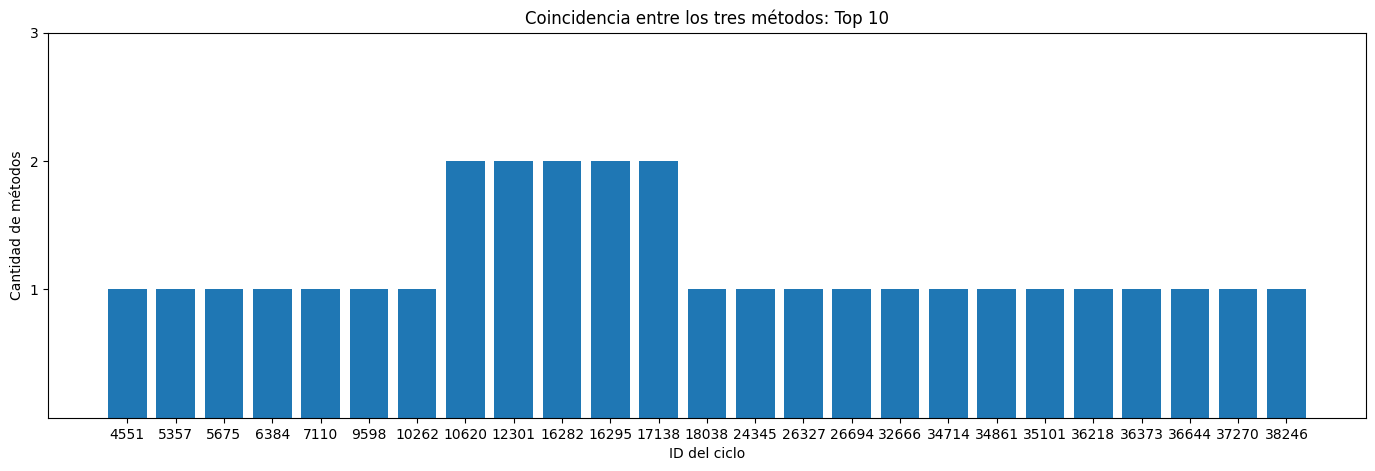

In [46]:
#A continuación una comparación entre los 3 métodos con el fin de observar cuáles fueron los resultados en común:
#Importación de matplotlib para gráficos
#!pip install matplotlib
import matplotlib.pyplot as plt

#Top 10:

top10_m = set(df.nlargest(10, 'mahalanobis_2')['id'])
top10_lof = set(df.nlargest(10, 'lof')['id'])
top10_if = set(df.nlargest(10, 'isolation_forest')['id'])
ids = sorted(top10_m | top10_lof | top10_if)
frecuencia = [sum(i in grupo for grupo in [top10_m, top10_lof, top10_if]) for i in ids]

plt.figure(figsize=(17, 5))
plt.bar([str(i) for i in ids], frecuencia)
plt.xlabel('ID del ciclo')
plt.ylabel('Cantidad de métodos')
plt.title('Coincidencia entre los tres métodos: Top 10')
plt.yticks([1, 2, 3])
plt.show()

Se encontraron 5 outliers, respecto a los cuales es menester realizar una investigación a los fines de identificar posibles causas del origen de los mismos y tomar decisiones con respecto a si imputar, o eliminar registros o valores específicos.
Primero se visualizarán los mismos en un dataframe aislando las variables:

In [47]:
#intersección de conjuntos
df_outliers_5 = pd.DataFrame({"Art": ids,"Frecuencia Union 2": frecuencia}).sort_values("Frecuencia Union 2",ascending = False).head(5)
print(df_outliers_5)


#Conversión de los Números de artículo con métodos coincidentes a lista:
list_outliers_5 = df_outliers_5["Art"].to_list()
print(f"\n{list_outliers_5}")


      Art  Frecuencia Union 2
7   10620                   2
8   12301                   2
11  17138                   2
10  16295                   2
9   16282                   2

[10620, 12301, 17138, 16295, 16282]


In [48]:
#Filtrado del dataframe para los artículos con métodos coincidentes:
df[df["id"].isin(list_outliers_5)]



,id,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens,num_hrefs,num_self_hrefs,num_imgs,num_videos,...,title_subjectivity,title_sentiment_polarity,abs_title_subjectivity,abs_title_sentiment_polarity,shares,mahalanobis_2,lof,atipico_lof,isolation_forest,atipico_if
10619,10620,11.0,358.0,0.575581393676,0.999999995146,0.733009705180,8.0,6.0,1.0,0.0,...,0.233333333333,0.0666666666667,0.266666666667,0.0666666666667,20000,6455.626652941580687,7.938247608181176,True,-0.061038640742096,False
12300,12301,9.0,200.0,0.572864318729,0.999999991597,0.714285708283,5.0,3.0,0.0,1.0,...,0.700000000000,-0.0500000000000,0.200000000000,0.0500000000000,478,6332.077420764459021,11.228104459399979,True,-0.020498353948904,False
16281,16282,8.0,192.0,0.697297293528,0.999999992857,0.735714280459,13.0,1.0,0.0,1.0,...,1.000000000000,-0.5000000000000,0.500000000000,0.5000000000000,17300,6216.935396696027055,17.756705406788488,True,-0.029958563933190,False
16294,16295,13.0,162.0,0.716049378296,0.999999990654,0.850467281771,8.0,7.0,0.0,0.0,...,0.450000000000,0.3000000000000,0.050000000000,0.3000000000000,555,12026.056951895083330,15.837117420828227,True,-0.001349070738165,False
17137,17138,11.0,478.0,0.573275860833,0.999999996377,0.768115939246,4.0,0.0,0.0,1.0,...,0.000000000000,0.0000000000000,0.500000000000,0.0000000000000,1300,8188.874912035916168,12.839278403783744,True,-0.071211623172457,False


Estos 5 artículos tienen una proporción de non-stop words que es prácticamente 1, lo cual es incongruente con un texto bien redactado, por lo que esto puede ser un error de imputación.

Estos registros formarán parte del análisis posterior en el análisis exploratorio y descriptivo, por lo que no se eliminarán aquí y formarán parte del análisis, sólo porque son de interés para el análisis.

## 3. ANÁLISIS EXPLORATORIO Y DESCRIPTIVO

### 3.1 Estadísticos descriptivos


In [49]:
# 3.1 Estadísticos descriptivos
# Resumen de las variables numericas: media, dispersion, rango y cuartiles.
pd.set_option('display.precision', 3)

estadisticos = df[cols_cuantitativas + ['shares']].describe().T
estadisticos = estadisticos[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']]

estadisticos

,count,mean,std,min,25%,50%,75%,max
n_tokens_title,39643.0,10.399,2.114,2.000,9.000,10.000,12.000,23.000
n_tokens_content,39643.0,546.489,471.085,0.000,246.000,409.000,716.000,8474.000
n_unique_tokens,39643.0,0.531,0.137,0.000,0.471,0.539,0.609,1.000
n_non_stop_words,39643.0,0.970,0.170,0.000,1.000,1.000,1.000,1.000
n_non_stop_unique_tokens,39643.0,0.673,0.154,0.000,0.626,0.690,0.755,1.000
average_token_length,39643.0,4.548,0.844,0.000,4.478,4.664,4.855,8.042
num_keywords,39643.0,7.224,1.909,1.000,6.000,7.000,9.000,10.000
num_hrefs,39643.0,10.884,11.332,0.000,4.000,8.000,14.000,304.000
num_self_hrefs,39643.0,3.293,3.855,0.000,1.000,3.000,4.000,116.000
num_imgs,39643.0,4.543,8.306,0.000,1.000,1.000,4.000,128.000


Los estadísticos descriptivos muestran que las variables del dataset presentan escalas, rangos y niveles de dispersión heterogéneos. El análisis de medidas como la media, la mediana, los cuartiles y la desviación estándar permite caracterizar su comportamiento, identificar posibles asimetrías y detectar valores extremos. Estas diferencias son relevantes para comprender la estructura de los datos y orientar las decisiones de preparación y selección de variables para el posterior modelado predictivo.

In [50]:
# Seleccionamos un subconjunto de variables con interpretación directa en
# términos de "qué hace popular a un artículo", para el análisis descriptivo.
variables_interes = [c for c in [
    "n_tokens_content", "num_hrefs", "num_imgs", "num_videos",
    "num_keywords", "average_token_length", "global_sentiment_polarity",
    "title_subjectivity", "kw_avg_avg"
] if c in df.columns]

df[variables_interes].describe().T


,count,mean,std,min,25%,50%,75%,max
n_tokens_content,39643.0,546.489,471.085,0.000,246.000,409.000,716.000,8474.000
num_hrefs,39643.0,10.884,11.332,0.000,4.000,8.000,14.000,304.000
num_imgs,39643.0,4.543,8.306,0.000,1.000,1.000,4.000,128.000
num_videos,39643.0,1.250,4.108,0.000,0.000,0.000,1.000,91.000
num_keywords,39643.0,7.224,1.909,1.000,6.000,7.000,9.000,10.000
average_token_length,39643.0,4.548,0.844,0.000,4.478,4.664,4.855,8.042
global_sentiment_polarity,39643.0,0.119,0.097,-0.394,0.058,0.119,0.178,0.728
title_subjectivity,39643.0,0.282,0.324,0.000,0.000,0.150,0.500,1.000
kw_avg_avg,39643.0,3135.864,1318.167,0.000,2382.443,2870.047,3600.312,43567.660


|Dimensión|	Variables|	Qué permiten explorar|
| :--- | :--- | :--- |
| **Extensión del contenido** |	n_tokens_content, average_token_length.	| Longitud del artículo y longitud media de sus palabras. |
| **Enlaces y recursos visuales** |	num_hrefs, num_imgs, num_videos.	| Incorporación de enlaces, imágenes y videos. |
| **Organización temática** | num_keywords, kw_avg_avg.	| Cantidad de palabras clave y promedio de popularidad de las palabras clave. |
| **Sentimiento y subjetividad** |	global_sentiment_polarity, title_subjectivity.	| Polaridad del contenido y subjetividad del título. |

#### `Justificación de inclusión` ####

Para profundizar el análisis descriptivo, se seleccionó un subconjunto de nueve variables que representan diferentes dimensiones de los artículos: extensión del contenido, recursos multimedia, enlaces, organización temática y características subjetivas y emocionales. La selección busca facilitar la interpretación de los datos y explorar posibles factores asociados con la cantidad de veces que se comparte un artículo (`shares`). Estas variables se consideran candidatas para el posterior análisis predictivo, sin asumir de antemano que todas tendrán capacidad explicativa.


### 3.2 Análisis de la variable objetivo: `shares`


In [51]:

# 3.2 Análisis de la variable objetivo: shares
# Se resumen los principales momentos de la distribución y
# se grafican sus medidas más importantes.

resumen_shares = df['shares'].describe()
percentiles_shares = df['shares'].quantile([0.01, 0.05, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99])

print('Resumen estadístico de shares:')
print(resumen_shares)
print("Asimetría:", df["shares"].skew())

print()

print('Percentiles relevantes:')
print(percentiles_shares)


Resumen estadístico de shares:
count     39643.000
mean       3395.317
std       11627.091
min           1.000
25%         946.000
50%        1400.000
75%        2800.000
max      843300.000
Name: shares, dtype: float64
Asimetría: 33.96353222939705

Percentiles relevantes:
0.01      381.0
0.05      584.0
0.25      946.0
0.50     1400.0
0.75     2800.0
0.90     6200.0
0.95    10800.0
0.99    31658.0
Name: shares, dtype: float64




`distribución está sesgada hacia la derecha`:
La media es de 3.395 shares, mientras que la mediana es de apenas 1.400. Esto sugiere que algunos artículos con muchísimos compartidos elevan el promedio.




`La mitad de los artículos tiene 1.400 shares o menos`:
La mediana divide las observaciones en dos mitades: aproximadamente el 50% tiene hasta 1.400 compartidos y el otro 50% tiene al menos esa cantidad.




`Gran dispersión`:
La desviación estándar es de aproximadamente 11.627 shares, más de tres veces la media. Esto indica una variabilidad muy elevada, aunque parte de ella puede deberse a valores extremos.




`Artículos extraordinariamente populares`:
El máximo es de 843.300 shares, frente a una mediana de 1.400. El máximo equivale a más de 600 veces la mediana, lo que sugiere la presencia de valores extremos.

`Funcion Calcular_bins`:
funcion que calcula los bins para la cantidad de corte  que queremos por intervalo

In [52]:
def calcular_bins(df, columna, tamaño_intervalo):
    valor_maximo = df[columna].max()
    # Convertimos a int porque NumPy devuelve un float (ej: 800.0) y 'bins' requiere un entero
    return int(np.ceil(valor_maximo / tamaño_intervalo))
print(f"la cantidad bins para la columna shares con  intervalos de 3000 es {calcular_bins(df,"shares",3000)}")

la cantidad bins para la columna shares con  intervalos de 3000 es 282


Esta función queda definida como utilidad general para binning de ancho fijo; en los histogramas que siguen se usa, en cambio, un número de bins elegido manualmente (`bins=60`) por legibilidad visual, no el valor de 282 que calcularía `calcular_bins(df, "shares", 3000)` para el rango completo. Se deja la función disponible por si se la necesita más adelante para un binning equiespaciado.

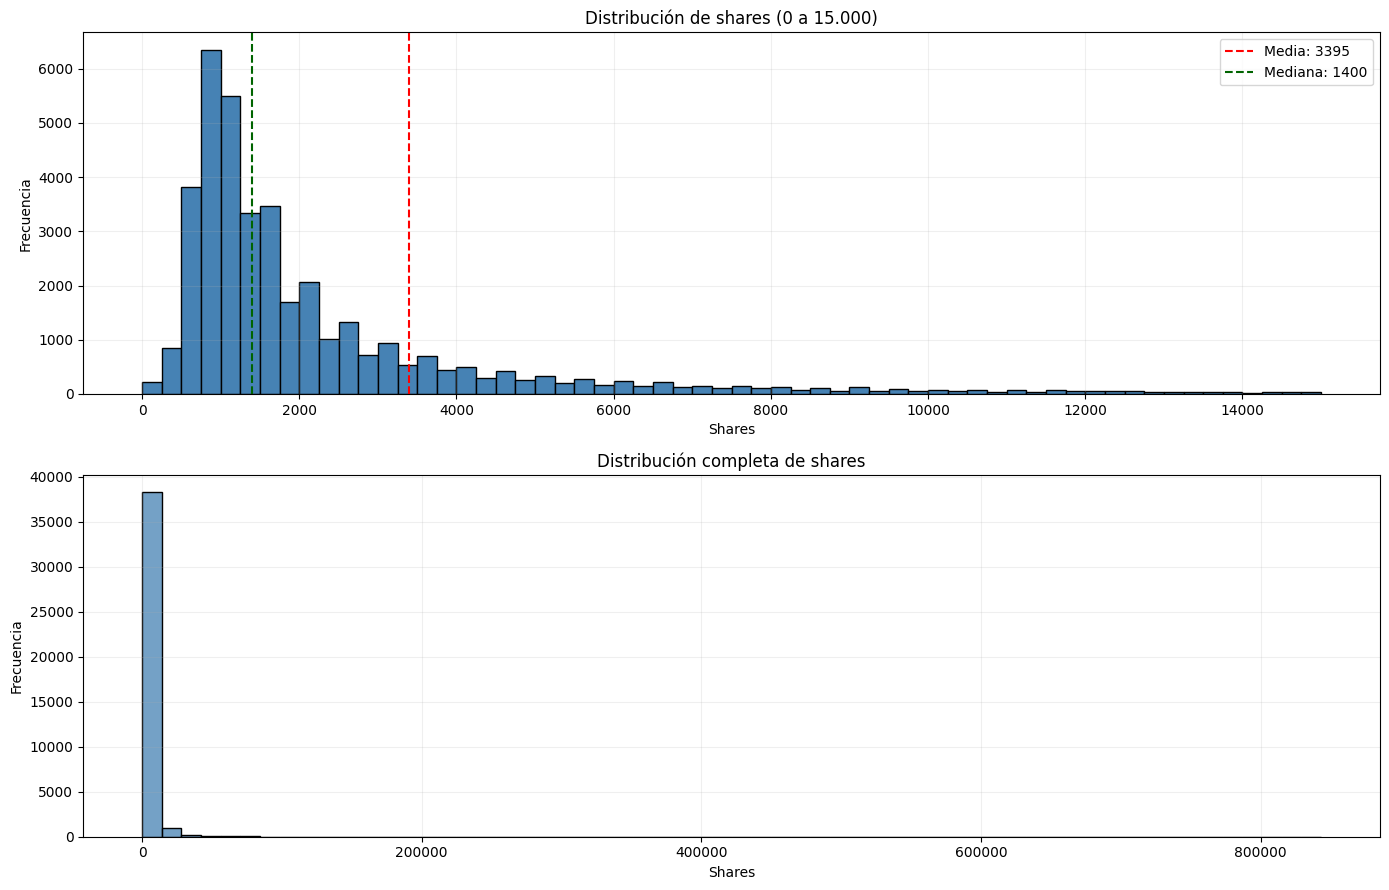

In [53]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 1, figsize=(14, 9))

media = df["shares"].mean()
mediana = df["shares"].median()

# Histograma de la zona principal
df["shares"].hist(
    bins=60,
    range=(0, 15000),
    ax=axes[0],
    color="steelblue",
    edgecolor="black"
)

axes[0].axvline(
    media,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label=f"Media: {media:.0f}"
)

axes[0].axvline(
    mediana,
    color="darkgreen",
    linestyle="--",
    linewidth=1.5,
    label=f"Mediana: {mediana:.0f}"
)

axes[0].set_title("Distribución de shares (0 a 15.000)")
axes[0].set_xlabel("Shares")
axes[0].set_ylabel("Frecuencia")
axes[0].legend()
axes[0].grid(alpha=0.2)

# Histograma de la distribución completa
sns.histplot(
    data=df,
    x="shares",
    bins=60,
    ax=axes[1],
    color="steelblue",
    edgecolor="black"
)

axes[1].set_title("Distribución completa de shares")
axes[1].set_xlabel("Shares")
axes[1].set_ylabel("Frecuencia")
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

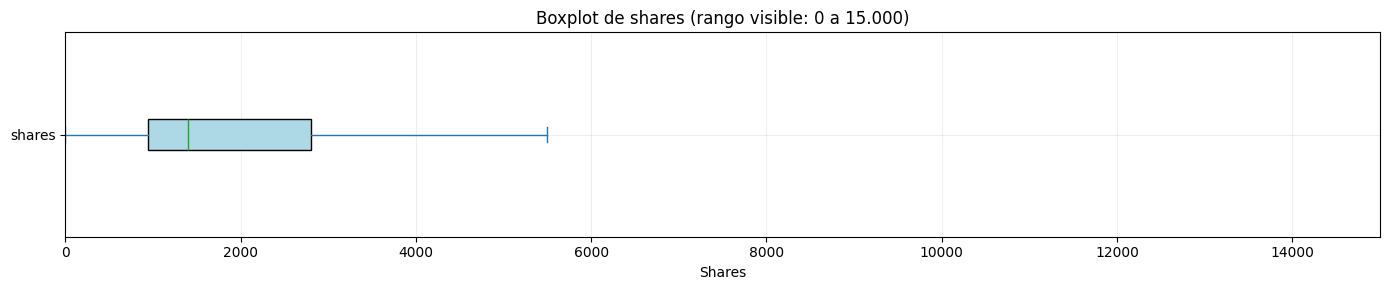

In [54]:
plt.figure(figsize=(14, 3))

df["shares"].plot.box(
    vert=False,
    patch_artist=True,
    boxprops=dict(facecolor="lightblue"),
    showfliers=False
)

plt.xlim(0, 15000)
plt.title("Boxplot de shares (rango visible: 0 a 15.000)")
plt.xlabel("Shares")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

\[
RIC = Q3-Q1=2800-946=1854
\]

\[
Límite superior=2800+1.5(1854)=5581
\]

Por lo tanto, los artículos con más de 5.581 shares se consideran potenciales valores atípicos según este criterio.
Esto no significa necesariamente que sean errores: podrían representar artículos que alcanzaron una popularidad excepcional.

La variable *shares* presenta una distribución fuertemente asimétrica hacia la derecha, caracterizada por una elevada concentración de observaciones en valores bajos y la presencia de valores extremos superiores.

La media (3.395) es considerablemente mayor que la mediana (1.400), lo que evidencia la influencia de artículos con una cantidad excepcionalmente alta de compartidos.

Asimismo, el 50 % central de las observaciones se encuentra entre 946 y 2.800 shares, mientras que el valor máximo alcanza los 843.300, reflejando una importante dispersión.

En consecuencia, `la mediana resulta más representativa que la media para describir el comportamiento típico de la variable shares`, debido a su menor sensibilidad a los valores extremos.

se realizaron dos graficos con diferentes limites debido a que no era claro visualmente tener un unico grafico por valores muy atipicos(mayores a 100000)

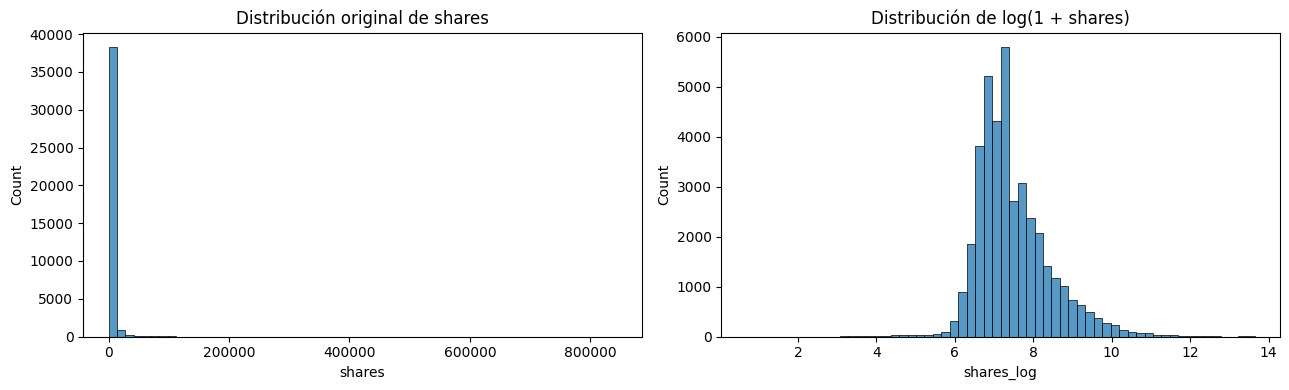

In [55]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
#nos permite acceder a dos graficos

sns.histplot(df["shares"], bins=60, ax=axes[0])#ax=axes[0]: es el primer grafico (el de la izquierda)
axes[0].set_title("Distribución original de shares")

df["shares_log"] = np.log1p(df["shares"])

sns.histplot(df["shares_log"], bins=60, ax=axes[1])
axes[1].set_title("Distribución de log(1 + shares)")

plt.tight_layout()
plt.show()


Se crea una nueva variable, `shares_log`, mediante la transformación logarítmica `log1p(shares)`. Esta decisión se fundamenta en la elevada asimetría positiva de la variable

original y en la presencia de valores extremos. La transformación reduce la escala de los valores más elevados, lo que puede facilitar el entrenamiento de modelos predictivos y

disminuir la influencia de las diferencias absolutas extremas. Se conserva la variable original para interpretar los resultados en términos de cantidad de compartidos y

comparar el desempeño de los modelos con y sin transformación.

In [56]:
# Casos atípicos estadísticos según IQR (umbral = Q3 + 1.5*RIC = 2800 + 1.5*1854 = 5581,
# tal como se calculó en la celda anterior; antes decía 5574 por error de transcripción).
outliers_iqr = df[df['shares'] > 5581]
# Casos ultra virales (corte editorial, no estadístico: artículos que multiplican
# muchas veces el límite anterior).
ultra_virales = df[df['shares'] > 50000]
print(f"outliers iqr:{len(outliers_iqr)} y ultravirales: {len(ultra_virales)}")


outliers iqr:4540 y ultravirales: 203


La variable `shares` confirma, con evidencia numérica, el diagnóstico cualitativo de 3.1: asimetría positiva muy fuerte (coeficiente de asimetría ≈ 34), media muy por encima de la mediana y una cola derecha extensa que llega hasta 843.300 shares frente a una mediana de apenas 1.400. El criterio de Tukey (Q3 + 1,5·RIC = 5.581) y el corte editorial de "ultra viral" (> 50.000) reportados en la celda anterior cuantifican cuántos artículos caen en esa cola; ninguno de esos registros debe eliminarse sin revisión, porque no hay evidencia de que sean errores de carga y sí de que representan episodios reales de alta viralidad. Esta asimetría es la razón concreta por la que se trabaja con `shares_log = log1p(shares)` en el resto del análisis y en el modelado: comprime la escala sin descartar información y permite que los supuestos de los modelos lineales sean más razonables.


### 3.3 Distribución de las variables


A partir de las nueve variables seleccionadas en 3.1 (`variables_interes`), se eligieron cinco para representar gráficamente sus distribuciones: `n_tokens_content`, `num_hrefs`, `num_imgs`, `average_token_length` y `global_sentiment_polarity`. Además, se incorporaron dos variables que no forman parte de ese conjunto original —`n_tokens_title` (extensión del título) e `is_weekend` (publicación en fin de semana)— porque aportan una lectura estructural y temporal directa que complementa a las nueve seleccionadas, y porque `is_weekend` se retoma más adelante al plantear hipótesis sobre el día de publicación (sección 4.3). Las cuatro variables restantes de 3.1 (`num_videos`, `num_keywords`, `title_subjectivity`, `kw_avg_avg`) no se graficaron para evitar una presentación excesivamente extensa, pero sus medidas descriptivas ya se calcularon y presentaron en 3.1.


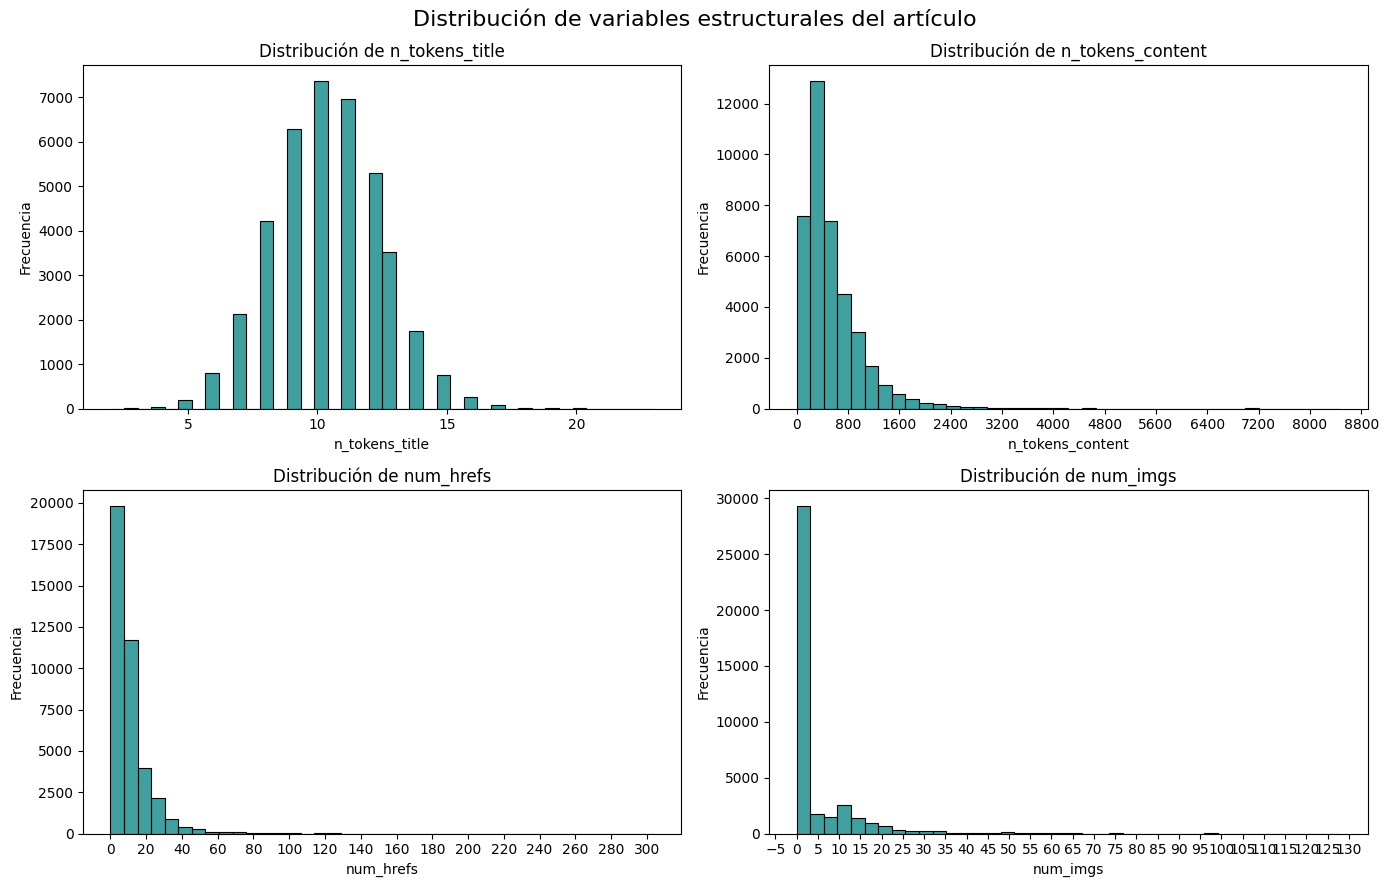

In [57]:

import matplotlib.ticker as ticker
import os

os.makedirs("imagenes", exist_ok=True)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()

variables_1 = [
    "n_tokens_title",
    "n_tokens_content",
    "num_hrefs",
    "num_imgs"
]

for i, col in enumerate(variables_1):
    sns.histplot(
        data=df,
        x=col,
        bins=40,
        ax=axes[i],
        color="teal",
        edgecolor="black"
    )

    axes[i].set_title(f"Distribución de {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Frecuencia")

# Ajustes de los ejes X
axes[0].xaxis.set_major_locator(ticker.MultipleLocator(5))
axes[1].xaxis.set_major_locator(ticker.MultipleLocator(800))
axes[2].xaxis.set_major_locator(ticker.MultipleLocator(20))
axes[3].xaxis.set_major_locator(ticker.MultipleLocator(5))

fig.suptitle(
    "Distribución de variables estructurales del artículo",
    fontsize=16
)

plt.tight_layout()
plt.savefig(
    "imagenes/distribucion_estructura_articulo.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

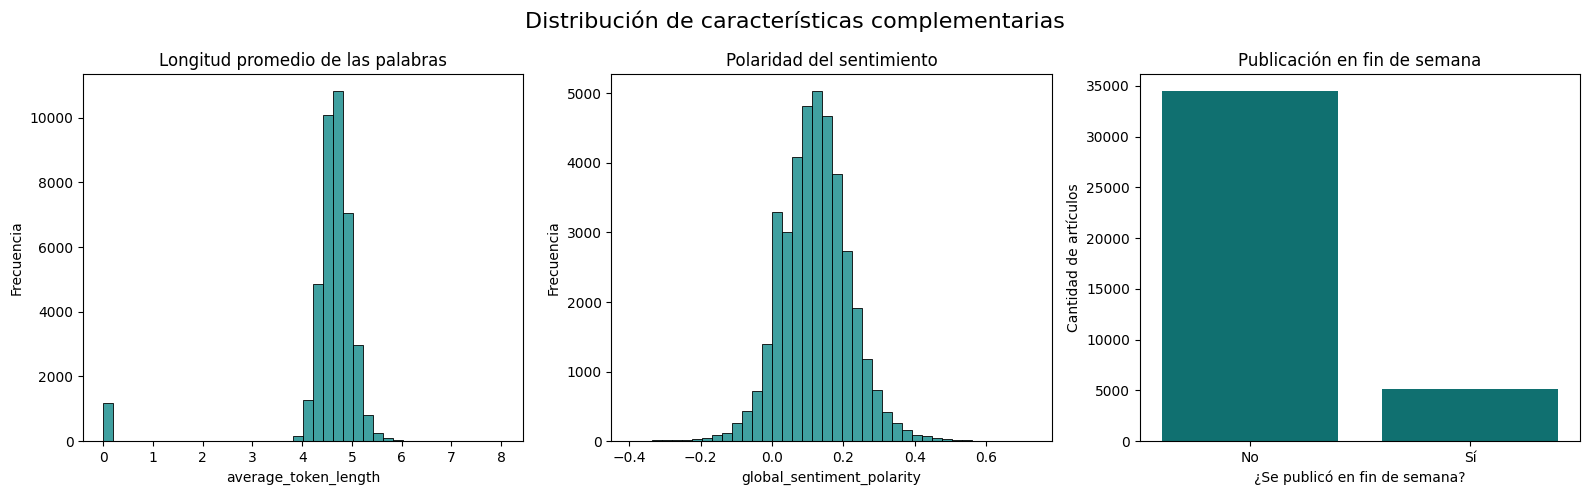

In [58]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

variables_2 = [
    "average_token_length",
    "global_sentiment_polarity",
    "is_weekend"
]

# Longitud promedio de las palabras
sns.histplot(
    data=df,
    x="average_token_length",
    bins=40,
    ax=axes[0],
    color="teal",
    edgecolor="black"
)
axes[0].set_title("Longitud promedio de las palabras")
axes[0].set_xlabel("average_token_length")
axes[0].set_ylabel("Frecuencia")

# Polaridad del sentimiento
sns.histplot(
    data=df,
    x="global_sentiment_polarity",
    bins=40,
    ax=axes[1],
    color="teal",
    edgecolor="black"
)
axes[1].set_title("Polaridad del sentimiento")
axes[1].set_xlabel("global_sentiment_polarity")
axes[1].set_ylabel("Frecuencia")

# Publicación en fin de semana
sns.countplot(
    data=df,
    x="is_weekend",
    ax=axes[2],
    color="teal"
)
axes[2].set_title("Publicación en fin de semana")
axes[2].set_xlabel("¿Se publicó en fin de semana?")
axes[2].set_ylabel("Cantidad de artículos")
axes[2].set_xticks([0, 1], labels=["No", "Sí"])

fig.suptitle(
    "Distribución de características complementarias",
    fontsize=16
)

plt.tight_layout()
plt.savefig(
    "imagenes/distribucion_caracteristicas_complementarias.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## Interpretación de los gráficos

El conjunto de datos contiene **39.643 observaciones**. Previamente, se calcularon los estadísticos descriptivos de las variables seleccionadas, cuyos valores de media, mediana, cuartiles y máximos se utilizan como referencia para la interpretación. Los histogramas permiten visualizar la forma de las distribuciones de las variables representadas, mientras que el gráfico de barras permite comparar la frecuencia de publicación entre días de semana y fines de semana. Como se aclaró en 3.3, dos de las variables graficadas (`n_tokens_title` e `is_weekend`) no forman parte del conjunto original de nueve variables de 3.1, sino que se agregaron para completar la lectura estructural y temporal.

No todas las variables seleccionadas fueron incluidas en los gráficos. Por este motivo, las variables `num_videos`, `num_keywords`, `title_subjectivity` y `kw_avg_avg` se describen a partir de sus estadísticos descriptivos, sin atribuirles patrones visuales que no se observan en las figuras.

### Figura 1. Distribución de variables estructurales del artículo

- **Extensión del artículo (`n_tokens_content`):** el promedio es de **546,5 palabras** y la mediana de **409**. La mitad central de los artículos tiene entre **246 y 716 palabras**. El histograma muestra una distribución marcadamente asimétrica hacia la derecha: la mayoría de los artículos se concentra en longitudes relativamente bajas, mientras que unos pocos presentan extensiones mucho mayores, con un máximo de **8.474 palabras**. Por esta razón, la mediana representa mejor la extensión de un artículo típico que el promedio.

- **Cantidad de enlaces (`num_hrefs`):** la mediana es de **8 enlaces**, con un primer cuartil de **4** y un tercer cuartil de **14**. El máximo alcanza los **304 enlaces**. Esta diferencia entre los valores centrales y el máximo sugiere una distribución con una cola hacia valores altos. Por lo tanto, la cantidad de enlaces varía entre artículos y algunos casos extremos pueden influir en el promedio.

- **Cantidad de imágenes (`num_imgs`):** la mediana es de **1 imagen** y el tercer cuartil es de **4**, mientras que el máximo alcanza las **128 imágenes**. El histograma concentra muchas observaciones en cantidades bajas y presenta una cola hacia valores altos. El promedio de **4,5 imágenes** resulta superior a la mediana, lo que es consistente con la influencia de artículos que contienen muchas imágenes.

- **Cantidad de palabras en el título (`n_tokens_title`):** el histograma permite observar cómo se distribuye la extensión de los títulos. Su interpretación debe complementarse con los estadísticos descriptivos para identificar el valor típico, la dispersión y la posible presencia de valores extremos.

### Figura 2. Distribución de características complementarias

- **Longitud promedio de las palabras (`average_token_length`):** la mediana es de **4,66 caracteres** y el promedio de **4,55**. La proximidad entre ambos valores sugiere que las medidas de tendencia central son relativamente similares, aunque la forma de la distribución debe evaluarse a partir del histograma.

- **Polaridad global del sentimiento (`global_sentiment_polarity`):** la distribución se centra alrededor de **0,12**, con una mediana de **0,119**. El histograma permite observar la concentración de los valores y la presencia de observaciones tanto negativas como positivas. La polaridad resume la orientación sentimental del texto, pero no permite determinar por sí sola si un artículo será más popular.

- **Día de publicación (`is_weekend`):** el gráfico de barras muestra una mayor cantidad de publicaciones durante los días de semana que durante los fines de semana. Las barras representan cantidades de artículos, no tasas de compartidos ni niveles de popularidad.

### Variables no representadas gráficamente

Las siguientes variables fueron consideradas en los estadísticos descriptivos, pero no se incluyeron en las figuras:

- **Cantidad de videos (`num_videos`):** la mediana es **0** y el tercer cuartil es **1**, lo que indica que al menos la mitad de los artículos no contiene videos y que el 75 % registra, como máximo, un video.

- **Cantidad de palabras clave (`num_keywords`):** la distribución de los valores descriptivos se concentra entre **6 y 9 palabras clave** (Q1: 6; mediana: 7; Q3: 9), con un rango observado de 1 a 10.

- **Subjetividad del título (`title_subjectivity`):** la mediana es **0,15** y el tercer cuartil es **0,50**, lo que indica variabilidad en los valores de subjetividad asignados a los títulos.

- **Promedio de popularidad de palabras clave (`kw_avg_avg`):** la mediana es **2.870** y el 75 % de los casos no supera **3.600**, mientras que el máximo llega a **43.568**. La diferencia entre el promedio (**3.136**) y la mediana sugiere la posible influencia de valores altos. Esta variable resume el promedio de popularidad de las palabras clave del artículo y no debe confundirse con la cantidad de compartidos (`shares`).

### Conclusión

Las variables presentan diferentes patrones de distribución. La extensión de los artículos, la cantidad de enlaces y la cantidad de imágenes muestran indicios de colas hacia valores altos, por lo que sus promedios pueden diferir de los valores típicos. Los estadísticos descriptivos de las variables no representadas gráficamente también permiten identificar diferencias en la cantidad de videos, palabras clave y en las características del título y de las palabras clave.

En cambio, la polaridad global se concentra alrededor de valores ligeramente positivos, mientras que las publicaciones de días de semana son más numerosas que las de fines de semana.

Estas observaciones son **descriptivas**: los histogramas y los estadísticos univariados no permiten concluir que una característica cause más compartidos ni establecer por sí solos su asociación con `shares`. Estas relaciones deberán analizarse posteriormente mediante técnicas bivariadas y modelos predictivos. Asimismo, los valores extremos no deben eliminarse sin comprobar antes si representan errores o casos válidos.


**`Aclaración metodológica`:** Los valores de la media, la mediana, los cuartiles y los máximos mencionados en la siguiente interpretación se obtuvieron de la tabla de estadísticos descriptivos presentada en la sección anterior. Los histogramas complementan esos resultados al permitir visualizar la forma de las distribuciones, su asimetría y la concentración de las observaciones. Por su parte, el gráfico de barras permite comparar la frecuencia de publicación entre días de semana y fines de semana.

### 3.4 Análisis de relaciones entre variables




Antes de acotar el análisis a un subconjunto de variables, se lista el conjunto completo de variables cuantitativas disponibles (`cols_cuantitativas`), para que quede explícito a partir de qué universo se eligieron las seis que se usan en la matriz de dispersión siguiente.

In [59]:
print(cols_cuantitativas)
#vars_relacion = cols_cuantitativas + ['shares']

['n_tokens_title', 'n_tokens_content', 'n_unique_tokens', 'n_non_stop_words', 'n_non_stop_unique_tokens', 'average_token_length', 'num_keywords', 'num_hrefs', 'num_self_hrefs', 'num_imgs', 'num_videos', 'kw_min_min', 'kw_max_min', 'kw_avg_min', 'kw_min_max', 'kw_max_max', 'kw_avg_max', 'kw_min_avg', 'kw_max_avg', 'kw_avg_avg', 'self_reference_min_shares', 'self_reference_max_shares', 'self_reference_avg_sharess', 'LDA_00', 'LDA_01', 'LDA_02', 'LDA_03', 'LDA_04', 'global_subjectivity', 'global_sentiment_polarity', 'global_rate_positive_words', 'global_rate_negative_words', 'rate_positive_words', 'rate_negative_words', 'avg_positive_polarity', 'min_positive_polarity', 'max_positive_polarity', 'avg_negative_polarity', 'min_negative_polarity', 'max_negative_polarity', 'title_subjectivity', 'title_sentiment_polarity', 'abs_title_subjectivity', 'abs_title_sentiment_polarity']


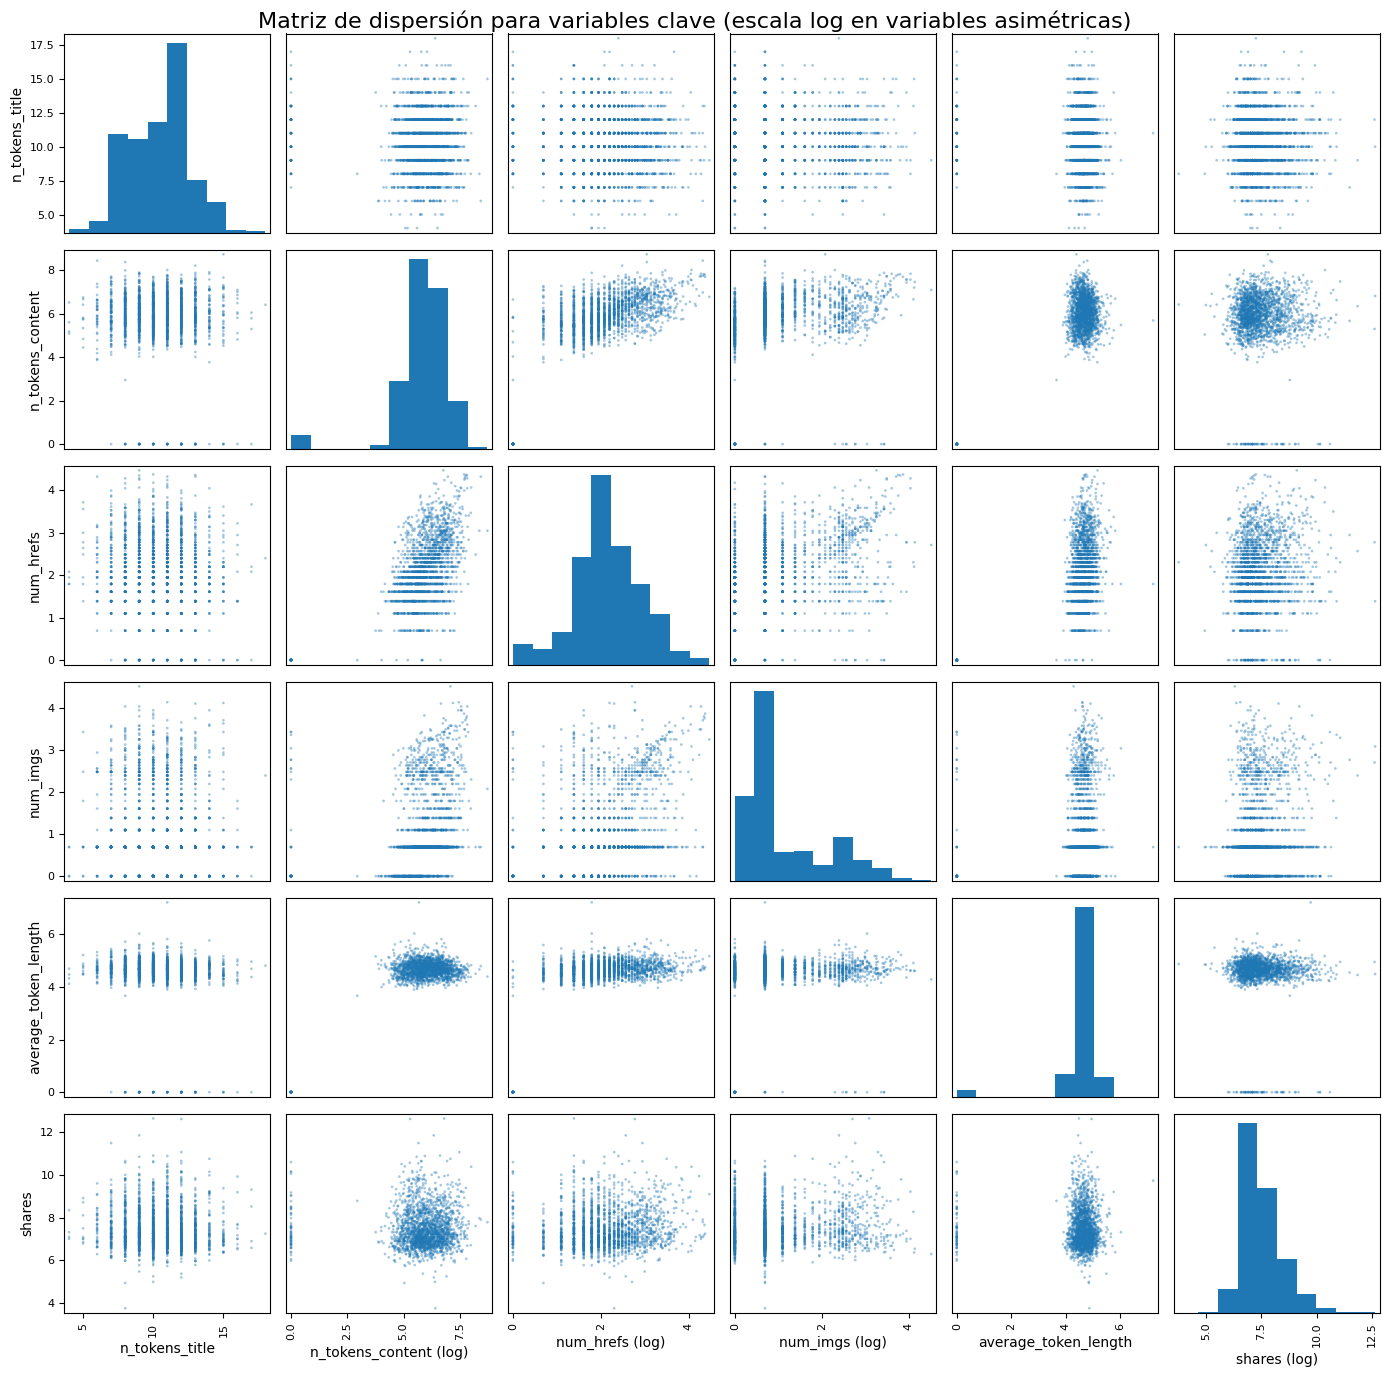

In [60]:
vars_relacion = ['n_tokens_title', 'n_tokens_content', 'num_hrefs', 'num_imgs', 'average_token_length', 'shares']
muestra = df[vars_relacion].sample(n=min(2000, len(df)), random_state=42).copy()

# log1p evita problemas con ceros (log(0) no está definido) escala logarítmica
for col in ['n_tokens_content', 'num_hrefs', 'num_imgs', 'shares']:
    muestra[col] = np.log1p(muestra[col])

ejes = pd.plotting.scatter_matrix(muestra, figsize=(14, 14), alpha=0.4, diagonal='hist', s=15)
for ax in ejes.flatten():
    ax.set_xlabel(ax.get_xlabel() + ' (log)' if ax.get_xlabel() in ['n_tokens_content','num_hrefs','num_imgs','shares'] else ax.get_xlabel())
plt.suptitle('Matriz de dispersión para variables clave (escala log en variables asimétricas)', fontsize=16)
plt.tight_layout()
plt.savefig("imagenes/relaciones_entre_variables.png")
plt.show()


La matriz de dispersión confirma, a nivel bivariado, lo que ya se había detectado al mirar cada variable por separado: la fuerte asimetría de n_tokens_content, num_hrefs, num_imgs y shares no solo afecta sus distribuciones individuales, sino que también domina sus relaciones con las demás variables. En la escala original, la gran mayoría de los puntos queda comprimida cerca del origen en cualquier panel donde participe alguna de estas cuatro, mientras un puñado de observaciones extremas se despliega hacia la derecha o hacia arriba, lo que dificulta juzgar a simple vista si existe asociación lineal real.

Dentro de esa limitación, se pueden rescatar algunas lecturas:

n_tokens_content vs. num_hrefs y num_imgs: se insinúa una relación positiva débil — los artículos más largos tienden a tener algo más de enlaces e imágenes —, aunque la nube es ancha y con mucha dispersión, no una tendencia lineal marcada.
shares vs. el resto: no se observa ninguna relación bivariada clara con n_tokens_title, n_tokens_content, num_hrefs, num_imgs ni average_token_length. Los artículos con mayor cantidad de shares aparecen distribuidos en un rango amplio de valores de cada predictor, sin un patrón visual evidente. Esto es consistente con lo esperado dado que la variable objetivo mezcla factores no capturados por estas variables de contenido (viralidad, momento de publicación, difusión en redes).
average_token_length: no muestra relación aparente con ninguna otra variable, más allá del grupo de valores en 0 que ya se había señalado como un valor lógicamente imposible y que aparece alineado verticalmente/horizontalmente en varios paneles — otra razón para resolver ese problema de calidad antes de modelar.

Qué aporta esto para el modelo:

La ausencia de relaciones lineales visibles entre los predictores individuales y shares sugiere que un modelo lineal simple con pocas variables va a tener poder explicativo limitado — es coherente con R² bajos que suelen reportarse en este dataset y refuerza la necesidad de evaluar más predictores en conjunto (no solo este subconjunto de seis) y, eventualmente, modelos no lineales.
La dominancia visual de los outliers en estos gráficos es otra confirmación de que conviene aplicar transformación logarítmica a las variables de conteo y a shares antes de ajustar la regresión, tanto por mejorar los supuestos del modelo lineal como por hacer la relación entre variables más interpretable.
No se observa colinealidad fuerte entre estos seis predictores en particular (más allá de la relación débil n_tokens_content-num_hrefs/num_imgs), lo cual es un dato útil para la etapa de preparación de variables: el problema de multicolinealidad del dataset está concentrado en otras familias de variables (kw_*, LDA_*, self_reference_*), no en este grupo.

### 3.5 Matriz de correlación

El análisis se hace en tres pasos, cada uno con un propósito distinto: primero se calcula la correlación de `shares` (en su escala original) contra **todas** las variables cuantitativas, para tener un ranking completo sin descartar nada de antemano. Luego se repite ese cálculo incorporando `shares_log`, se compara con la versión original y se visualiza como mapa de calor completo (incluye también la multicolinealidad entre predictores). Por último, se arma un mapa de calor acotado a las nueve variables de interés de 3.1 más ambas versiones de `shares`, para una lectura más legible de ese subconjunto puntual.


In [61]:
# 3.5 Matriz de correlacion
# Calculamos la correlacion lineal entre las variables numericas para identificar asociaciones con la variable objetivo.
cols_corr = cols_cuantitativas + ['shares']
matriz_corr = df[cols_corr].corr().round(3)
matriz_corr

correlaciones_con_shares = (
    matriz_corr['shares'].drop(labels='shares')
    .sort_values(key=lambda s: s.abs(), ascending=False)
)
correlaciones_con_shares



,shares
kw_avg_avg,0.110
LDA_03,0.084
kw_max_avg,0.064
LDA_02,-0.059
self_reference_avg_sharess,0.058
self_reference_min_shares,0.056
self_reference_max_shares,0.047
kw_avg_max,0.045
num_hrefs,0.045
kw_min_avg,0.040


In [ ]:
# 3.5 Matriz de correlación


os.makedirs("imagenes", exist_ok=True)

# Transformación de la variable objetivo
df["shares_log"] = np.log1p(df["shares"])

# Evitar duplicados y mantener las variables cuantitativas
cols_corr = list(dict.fromkeys(cols_cuantitativas + ["shares", "shares_log"]))

# Matriz de correlación
matriz_corr = df[cols_corr].corr().round(3)

# Correlaciones con shares original
correlaciones_con_shares = (
    matriz_corr["shares"]
    .drop(labels=["shares", "shares_log"], errors="ignore")
    .sort_values(key=lambda s: s.abs(), ascending=False)
)

display(correlaciones_con_shares)

# Correlaciones con shares_log
correlaciones_con_shares_log = (
    matriz_corr["shares_log"]
    .drop(labels=["shares", "shares_log"], errors="ignore")
    .sort_values(key=lambda s: s.abs(), ascending=False)
)

display(correlaciones_con_shares_log)

# Matriz completa
plt.figure(figsize=(20, 18))

sns.heatmap(
    matriz_corr,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    annot=False,
    cbar_kws={"shrink": 0.6}
)

plt.title("Matriz de correlación entre variables cuantitativas")
plt.tight_layout()

plt.savefig(
    "imagenes/matriz_correlaciones_variables.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

,shares
kw_avg_avg,0.110
LDA_03,0.084
kw_max_avg,0.064
LDA_02,-0.059
self_reference_avg_sharess,0.058
self_reference_min_shares,0.056
self_reference_max_shares,0.047
kw_avg_max,0.045
num_hrefs,0.045
kw_min_avg,0.040


,shares_log
kw_avg_avg,0.222
LDA_02,-0.165
LDA_03,0.126
kw_min_avg,0.109
kw_max_avg,0.109
num_hrefs,0.105
num_imgs,0.091
self_reference_avg_sharess,0.087
self_reference_max_shares,0.077
global_subjectivity,0.075


In [ ]:
# 3.5 Matriz de correlación: variables clave


os.makedirs("imagenes", exist_ok=True)

# Las 9 variables seleccionadas
cols_clave = [
    "n_tokens_content",
    "num_hrefs",
    "num_imgs",
    "num_videos",
    "num_keywords",
    "average_token_length",
    "global_sentiment_polarity",
    "title_subjectivity",
    "kw_avg_avg"
]

# Agregamos las dos versiones de la variable objetivo
cols_corr_clave = cols_clave + ["shares", "shares_log"]

# Matriz de correlación
matriz_corr_clave = df[cols_corr_clave].corr().round(3)

# Visualización
plt.figure(figsize=(12, 10))

sns.heatmap(
    matriz_corr_clave,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt=".2f",
    square=True,
    cbar_kws={"shrink": 0.8}
)

plt.title("Matriz de correlación de las variables clave")
plt.tight_layout()

plt.savefig(
    "imagenes/matriz_correlaciones_variables_clave.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Conclusión

La matriz de correlación entre todas las variables cuantitativas muestra que la variable objetivo, **`shares`** (y su transformación **`shares_log`**), tiene correlaciones muy débiles con prácticamente todos los predictores: en la fila y columna de `shares` casi todo el mapa de calor es de tonos neutros (cercanos a 0).

Las asociaciones más visibles, aunque modestas, aparecen con:

- **Variables de keywords:** `kw_avg_avg`, `kw_max_avg` y `kw_avg_max`.
- **Referencias a artículos propios:** variables `self_reference_*`.
- **Temas LDA:** por ejemplo, `LDA_03` en positivo y `LDA_02` en negativo.

Al pasar a `shares_log` la señal mejora levemente, lo que confirma que la distribución de `shares` está muy sesgada y que conviene modelar en escala logarítmica. En conjunto, esto indica que ninguna variable explica por sí sola la popularidad de un artículo y que, si hay poder predictivo, vendrá de combinar muchas variables y de relaciones no lineales.

### Multicolinealidad entre predictores

Por otro lado, el mapa muestra bloques de **fuerte multicolinealidad entre los propios predictores**, que se ven como zonas rojas y azules intensas fuera de la diagonal:

- **Longitud y vocabulario del texto:** `n_unique_tokens`, `n_non_stop_words` y `n_non_stop_unique_tokens` están muy correlacionadas entre sí (cercanas a 0,9), y también con `average_token_length`. Son medidas casi redundantes.

- **Keywords:** `kw_max_min` y `kw_avg_min` presentan una correlación muy alta; `kw_max_avg` y `kw_avg_avg`, una correlación alta; y `kw_min_min` con `kw_max_max`, una correlación fuertemente negativa (cercana a -0,9).

- **Referencias propias:** `self_reference_min_shares`, `self_reference_max_shares` y `self_reference_avg_sharess` forman un bloque correlacionado.

- **Sentimiento y polaridad:** `global_rate_negative_words` con `rate_negative_words`; `global_sentiment_polarity` con `rate_positive_words` (positiva) y con `rate_negative_words` (negativa); `avg_negative_polarity` con `min_negative_polarity`; y `title_subjectivity` con `abs_title_sentiment_polarity`.

- **Temas LDA:** correlaciones negativas moderadas entre `LDA_00` y `LDA_04`, lo esperable en proporciones de tópicos que suman 1.


### Exploración de multicolinealidad


In [ ]:
# Comparación de correlaciones con shares: Pearson (original), Pearson (log).
cols_corr = (
    cols_cuantitativas
    + cols_canal_tematico
    + cols_dia_publicacion
)

# shares_log ya fue creado antes; si no existe en este punto, se recrea
df["shares_log"] = np.log1p(df["shares"])

comparacion_corr = pd.DataFrame({
    "pearson_shares":     df[cols_corr].corrwith(df["shares"], method="pearson"),
    "pearson_shares_log": df[cols_corr].corrwith(df["shares_log"], method="pearson"),

})

# Ordenamos por la magnitud de la correlación de SHARES
comparacion_corr = comparacion_corr.sort_values("pearson_shares", key=abs, ascending=False)

print(comparacion_corr.head(15).round(3))
print()
print("Máx. |r| por método:")
print(comparacion_corr.abs().max().round(3))

In [ ]:
#%pip install statsmodels
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Predictoras candidatas. Se excluyen las que son combinación lineal exacta de otras:
# - is_weekend (= sábado + domingo)
# - un día de la semana (los 7 suman 1, colisionan con la constante)
# - LDA_04 (los 5 LDA suman 1, colisionan con la constante)
cols_vif = (
    [c for c in cols_cuantitativas if c != "LDA_04"]
    + cols_canal_tematico
    + [c for c in cols_dia_publicacion if c not in ("weekday_is_sunday", "is_weekend")]
)

def calcular_vif(data, columnas):
    X = sm.add_constant(data[columnas].astype(float))
    vif = pd.Series(
        [variance_inflation_factor(X.values, i) for i in range(X.shape[1])],
        index=X.columns
    ).drop("const")
    return vif.sort_values(ascending=False)

vif_inicial = calcular_vif(df, cols_vif)
print(vif_inicial.head(20).round(1))

`calcular_vif()`:
1. Selecciona las columnas indicadas.
2. Convierte sus valores a tipo numérico (float).
3. Agrega una constante con sm.add_constant(), correspondiente al intercepto.
4. Calcula el factor de inflación de la varianza (VIF) de cada variable.
5. Excluye el VIF de la constante y ordena los resultados de mayor a menor.
El VIF mide cuánto se incrementa la varianza estimada del coeficiente de una variable debido a su relación lineal con las demás variables predictoras.

En términos generales:
- VIF cercano a 1: poca colinealidad lineal con las demás variables.
- VIF elevado: una variable puede estar explicada linealmente por otras predictoras, lo que dificulta distinguir sus efectos individuales.

In [ ]:
cols_cand = (
    [c for c in cols_cuantitativas if c != "LDA_04"]
    + cols_canal_tematico
    + [c for c in cols_dia_publicacion if c not in ("weekday_is_sunday", "is_weekend")]
)

corr_pred = df[cols_cand].corr().abs()

# Redundancia media de cada variable con las demás (no usa shares)
redundancia = (corr_pred.sum() - 1) / (len(cols_cand) - 1)

umbral_corr = 0.8
pares = [
    (a, b, corr_pred.loc[a, b])
    for i, a in enumerate(cols_cand)
    for b in cols_cand[i + 1:]
    if corr_pred.loc[a, b] > umbral_corr
]

a_eliminar = set()
for a, b, r in sorted(pares, key=lambda x: -x[2]):
    if a in a_eliminar or b in a_eliminar:
        continue
    # se descarta la más redundante con el resto
    a_eliminar.add(a if redundancia[a] > redundancia[b] else b)

cols_sin_multicol = [c for c in cols_cand if c not in a_eliminar]

print("Eliminadas:", sorted(a_eliminar))
print(calcular_vif(df, cols_sin_multicol).head(10).round(1))

El filtro automático por correlación (umbral 0,8) eliminó, entre otras, `kw_avg_avg`, `self_reference_avg_sharess` y `data_channel_is_world` — las tres habían sido señaladas en 3.1 como variables de interés por su interpretabilidad directa. Las celdas siguientes revisan caso por caso si esa eliminación automática es apropiada o si conviene reincorporarlas por criterio conceptual, antes de fijar el conjunto `cols_v2`.

In [ ]:
print(df[["data_channel_is_world", "LDA_02"]].corr().round(2))

`data_channel_is_world` y `LDA_02`

- `data_channel_is_world`: Pearson con `shares_log` de −0,152.
- `LDA_02`: Pearson de −0,165.
- Correlación entre ambas variables: 0,84.
    
    

 no se conservaría automáticamente ambas. Se probaría cada una por separado y compararía el rendimiento(en el apartado de entrenamiento).

`LDA_02`tiene una asociación individual ligeramente más fuerte con `shares_log`,

pero eso no demuestra que prediga mejor en conjunto con los demás atributos.

In [ ]:
print(df[["kw_avg_avg", "kw_min_avg", "kw_max_avg"]].corr().round(2))

- `kw_avg_avg`: Pearson con `shares_log` de 0,222; VIF inicial de 10,8.
- `kw_min_avg`: Pearson de 0,109; correlación con `kw_avg_avg` de 0,45 y con `kw_max_avg` de 0,09.
- `kw_max_avg`: Pearson de 0,109; correlación con `kw_avg_avg` de 0,81.

Se conservaría inicialmente `kw_avg_avg` por su mayor asociación con `shares_log`. Entre `kw_avg_avg` y `kw_max_avg`,

 se probaría un modelo sin cada una por separado. No  se descartaría `kw_min_avg` automáticamente,

 porque su relación con las otras dos es bastante menor

In [ ]:

# Ajustes por criterio conceptual
volver = ["kw_avg_avg", "self_reference_avg_sharess", "data_channel_is_world"]
sacar = [
    "kw_min_avg", "kw_max_avg",
    "self_reference_min_shares", "self_reference_max_shares",
    "rate_positive_words", "rate_negative_words",
    "LDA_02",  # solo si la correlación con world resultó > 0.8
]

cols_v2 = [c for c in cols_sin_multicol if c not in sacar] + volver
print(calcular_vif(df, cols_v2).head(10).round(1))

In [ ]:
# ¿Son redundantes las self_reference con su promedio?
print(df[["self_reference_avg_sharess",
          "self_reference_min_shares",
          "self_reference_max_shares"]].corr().round(2))



`self_reference_avg_sharess` tiene VIF inicial de 19,2.

La correlación entre la media y el mínimo es 0,82; entre la media y el máximo, 0,85.


se conservaria la media y eliminaria los extremos como primera alternativa porque la media presenta la asociación monotónica más fuerte con `shares_log` entre estas tres. Después verificaría el rendimiento predictivo

### Alcance del análisis exploratorio y selección de variables

El análisis de esta sección tiene como objetivo comprender la distribución de las variables, explorar su relación con la variable objetivo (`shares_log`) e identificar posibles redundancias entre los predictores. Para ello, se utilizan medidas de asociación, correlaciones y el factor de inflación de la varianza (VIF).

Los resultados permiten formular hipótesis preliminares sobre qué características podrían aportar información predictiva y qué variables podrían presentar multicolinealidad. Sin embargo, la asociación individual con la variable objetivo y la multicolinealidad entre predictores no determinan por sí solas la utilidad de una variable en el modelo.

Por lo tanto, las variables identificadas en esta etapa se consideran **candidatas iniciales**. La selección definitiva se realizará durante el desarrollo de los modelos predictivos, utilizando los datos de entrenamiento y comparando el desempeño de distintas combinaciones de variables mediante validación. El conjunto de prueba se reservará para la evaluación final del modelo seleccionado.

### 3.6 Principales hallazgos del análisis exploratorio

Los resultados del análisis descriptivo muestran que la popularidad de los artículos es altamente heterogénea. La variable objetivo `shares` presenta una distribución sesgada a la derecha, con una media superior a la mediana y una cola larga marcada, lo que indica la presencia de casos de difusión excepcional: la mayoría de las noticias obtiene un nivel de "compartidos" relativamente bajo, mientras que un pequeño conjunto logra una difusión desproporcionada.

Las variables predictoras analizadas también presentan distribuciones asimétricas y concentraciones en rangos bajos, con valores extremos que elevan la dispersión general. Sus relaciones con `shares`, evaluadas de forma individual, resultan débiles en todos los casos. Esto sugiere que ninguna variable aislada explica por sí sola la popularidad de un artículo, y que su capacidad predictiva —si existe— probablemente dependa de la combinación de múltiples factores relacionados con el contenido, la estructura del artículo y su forma de publicación.

Además, el análisis de multicolinealidad (3.5) identificó varios bloques de predictores fuertemente correlacionados entre sí —la familia `n_unique_tokens`/`n_non_stop_*`/`average_token_length`, los pares `kw_*`, el trío `self_reference_*_shares` y el par `data_channel_is_world`/`LDA_02`— que no deben incluirse todos juntos en un modelo lineal sin tratamiento, porque inflan la varianza de los coeficientes (VIF alto) y pueden volver inestable la estimación. El filtrado automático por correlación y el VIF dan un primer recorte razonable, pero en al menos tres casos (`kw_avg_avg`, `self_reference_avg_sharess`, `data_channel_is_world`) se optó por reincorporar la variable por criterio conceptual, dado que entre las mencionadas eran las más interpretables y las de mayor asociación con `shares_log` dentro de su grupo.

En conjunto, el análisis exploratorio indica que el problema de predicción no es trivial. La asimetría de la variable objetivo exige un tratamiento específico (transformación, análisis robusto a outliers), la debilidad de las relaciones bivariadas justifica avanzar hacia un modelo de regresión múltiple antes de sacar conclusiones sobre la linealidad del fenómeno, y la multicolinealidad detectada entre predictores obliga a tratar con cuidado qué variables conviven en el mismo modelo.


## 4. DEFINICIÓN DEL PROBLEMA PREDICTIVO




## 4. DEFINICIÓN DEL PROBLEMA PREDICTIVO

### 4.1 Pregunta de investigación, objetivo y variable objetivo

**Pregunta de investigación**

¿En qué medida las características de un artículo (contenido, estructura, temática, sentimiento y popularidad previa de sus palabras clave) permiten predecir la cantidad de veces que será compartido en redes sociales?

**Objetivo general**

Estimar la popularidad de los artículos de Mashable a partir de sus características, comparando dos enfoques: un modelo estadístico de regresión lineal múltiple, orientado a explicar qué variables se asocian con la cantidad de compartidos, y modelos de Machine Learning, orientados a maximizar la precisión predictiva.

**Objetivos específicos**

- Identificar qué características se asocian de forma significativa con la popularidad (sección 6).
- Evaluar la capacidad predictiva de dos modelos de Machine Learning mediante MAE, MSE, RMSE y R² sobre datos de prueba (sección 7).
- Comparar ambos enfoques en términos de interpretabilidad y precisión, y seleccionar el más adecuado para el problema (sección 8).

**Unidad de análisis y población**

Cada observación es un artículo publicado por Mashable durante un período de dos años. Luego de la limpieza (sección 2), la población de trabajo es de 39.643 artículos; de ella se extrae la muestra aleatoria de n = 750 utilizada en la sección 5.

**Variable objetivo**

La variable dependiente es `shares`, la cantidad de veces que un artículo fue compartido en redes sociales. Dado que su distribución es fuertemente asimétrica hacia la derecha (media de 3.395 frente a una mediana de 1.400, con un máximo de 843.300), el modelado se realizará principalmente sobre `shares_log = log(1 + shares)`. La variable original se conserva para interpretar los resultados en cantidad de compartidos y comparar el desempeño con y sin transformación.

**Variables predictoras**

Se utilizarán las familias de variables descriptas en la sección 1.6: estructura del artículo, enlaces y multimedia, canal temático, palabras clave, referencias a artículos propios, día de publicación, temas LDA y sentimiento/subjetividad. Se excluyen `url` y `timedelta` por ser no predictivas (sección 2.4). Las variables que superaron el análisis de multicolinealidad (sección 3.5) son *candidatas iniciales*: la selección definitiva se realizará en la etapa de modelado, comparando combinaciones sobre los datos de entrenamiento y reservando el conjunto de prueba para la evaluación final.

**Tipo de problema**

Regresión supervisada: se predice una variable cuantitativa a partir de múltiples variables explicativas.



### 4.2 Necesidad que busca resolver el modelo

Un medio de contenidos digitales como Mashable publica gran cantidad de artículos, pero no todos alcanzan la misma difusión. Un equipo editorial necesita saber qué características de sus notas se asocian con una mayor circulación en redes (extensión, cantidad de imágenes y videos, temática, tono del texto, día de publicación) para decidir cómo producir y cuándo publicar.

El modelo busca estimar, a partir de características conocidas al momento de redactar el artículo, cuántas veces podría compartirse, y ofrecer a la vez una lectura interpretable de qué factores se asocian con esa popularidad.

Se establecen dos límites desde el inicio:

- Las relaciones que se encuentren son **asociaciones, no causas**.
- El análisis exploratorio mostró correlaciones individuales débiles con `shares`, por lo que se anticipa un poder predictivo moderado y predicciones con margen de error considerable. Un modelo será útil si mejora una predicción de referencia simple (por ejemplo, predecir siempre la mediana).


### 4.3 Hipótesis iniciales

Cada hipótesis se vincula con variables concretas del dataset y se evaluará en las secciones 6 y 7 (signo y significatividad de los coeficientes, consistencia entre la muestra de 750 y la base completa, e importancia de variables en Machine Learning). Su planteo no implica causalidad.

| Hipótesis | Variables | Relación esperada | Evidencia exploratoria previa |
| :--- | :--- | :--- | :--- |
| **H1. Multimedia**: más imágenes y videos se asocian con más compartidos. | `num_imgs`, `num_videos` | Positiva | No se observó relación bivariada clara (3.4); se evaluará en el modelo multivariado. |
| **H2. Extensión**: la longitud del contenido se asocia con la popularidad. | `n_tokens_content`, `n_tokens_title` | Sin sentido definido a priori; puede ser no lineal | Distribución muy asimétrica; relación bivariada débil. |
| **H3. Temática**: la popularidad difiere según el canal temático y los temas del artículo. | `data_channel_is_*`, `LDA_*` | Diferencias entre temáticas | `data_channel_is_world` (r = −0,152) y `LDA_02` (r = −0,165) con `shares_log`; entre sí r = 0,84, por lo que se probarán por separado. |
| **H4. Sentimiento**: el tono emocional se asocia con los compartidos. | `global_sentiment_polarity`, `global_subjectivity` | Sin sentido definido a priori | Polaridad centrada en valores levemente positivos (~0,12). |
| **H5. Popularidad previa de keywords**: palabras clave que ya generaron muchos compartidos se asocian con más compartidos. | `kw_avg_avg` (y resto de `kw_*`) | Positiva | Mayor correlación individual con `shares_log` (r = 0,222). |

## 5. MUESTREO E INFERENCIA

### 5.1 Extracción de la muestra aleatoria de n = 750
### 5.2 Comparación muestra vs. población
### 5.3 Media de `shares`
### 5.4 Varianza de `shares`
### 5.5 Evaluación de la representatividad de la muestra




### 5.1 Extracción de la muestra aleatoria de n = 750

Este valor es arbitrario y es de interés a los fines de realizar el muestreo para la inferencia:
* si cambiar el tamaño de la muestra a la infrerencia poblacional con respecto a qué artículos serán los más populares.
* qué tipo de muestreo será el más adecuado:
  * Estratificado
  * Por conglomerados
  * Muestreo aleatorio simple
  * Muestreo Sistematizado

* Enfoque a ser utilizado:
  * Regresión logística
  * Regresión lineal

Llevándolo a los fines prácticos, se muestra a continuación la matriz de variables sujetas a evaluación para el muestreo:

In [ ]:
tipos_muestreo:list = ["Estratificado","Por conglomerados","Aleatorio Simple","Sistemático"]
tipos_regresion:list = ["Regresión Logística","Regresión Lineal"]

dict_muestreo:dict = dict()

for tr in tipos_regresion:
  dict_muestreo[tr] = tipos_muestreo

df_muestreo = pd.DataFrame(dict_muestreo)

df_muestreo



Para el análisis a ser desarrollado, se tendrán que aplicar diferentes criterios en base a los cuales utilizar un tipo de muestreo u otro.
Por otro lado, deberá variar también el tamaño de la muestra para evaluar cuál es el más adecuado en pos de la representatividad de la muestra.
Justamente: i no necesariamente de un fvalor = 750 (eng el muestreo).

In [ ]:
# 5.1 Extracción de la muestra
from scipy import stats
import os

df["shares_log"] = np.log1p(df["shares"])

N_POB = len(df)        # lee el tamaño completo de la poblacion
N_MUESTRA = 750        # tamaño de muestra por probar

# Muestreo aleatorio simple sin reposición, con semilla fija para reproducibilidad
muestra_750 = df.sample(n=N_MUESTRA, replace=False, random_state=42)

print(f"Tamaño de la población (N): {N_POB}")
print(f"Tamaño de la muestra (n):   {len(muestra_750)}")
print(f"Fracción de muestreo n/N:   {N_MUESTRA / N_POB:.2%}")
print(f"Artículos repetidos en la muestra: {muestra_750['id'].duplicated().sum()}")

# Factor de corrección por población finita
fcp = np.sqrt((N_POB - N_MUESTRA) / (N_POB - 1))
print(f"Factor de corrección por población finita: {fcp:.4f}")

##### **Articulo** **repetidos**: Esto confirma que la muestra fue realizada sin reposicion
##### **fraccion de muestreo**:  Ese 1.89% representa el porcentaje del muestreo que tomamos

#### **factor de correccion**: En este caso, el factor es 0,9905, prácticamente igual a 1. Esto se debe a que la fracción de muestreo es de apenas 1,89 %. Aplicar la corrección reduciría los errores estándar en menos de un 1% es decir, tu error es prácticamente el mismo que si la población fuera infinita: solo un 1 % más chico, estom se debe a que la muestra es muy chica



Se aplicará regresión logística dado que es la que mejores resultados ha dado en las correlaciones

In [ ]:
# Comparación de correlaciones con shares: Pearson (original), Pearson (log).
print(comparacion_corr.abs().max().round(3))

   ### 5.2 Comparación muestra vs. población

In [ ]:
# 5.2 a) Comparación de variables cuantitativas
vars_comp = [
    "shares", "shares_log",
    "n_tokens_content", "num_hrefs", "num_imgs", "num_videos",
    "kw_avg_avg", "global_sentiment_polarity"
]

comparacion_muestra = pd.DataFrame({
    "media_poblacion":   df[vars_comp].mean(),
    "media_muestra":     muestra_750[vars_comp].mean(),
    "mediana_poblacion": df[vars_comp].median(),
    "mediana_muestra":   muestra_750[vars_comp].median(),
    "desvio_poblacion":  df[vars_comp].std(ddof=0),
    "desvio_muestra":    muestra_750[vars_comp].std(ddof=1),
})

comparacion_muestra["dif_media_%"] = (
    comparacion_muestra["media_muestra"] / comparacion_muestra["media_poblacion"] - 1
) * 100

# Diferencia medida en desvíos de la población (permite comparar variables de distinta escala)
comparacion_muestra["dif_estandarizada"] = (
    (comparacion_muestra["media_muestra"] - comparacion_muestra["media_poblacion"])
    / comparacion_muestra["desvio_poblacion"]
)

display(comparacion_muestra.round(3))

desbalanceadas = comparacion_muestra.index[comparacion_muestra["dif_estandarizada"].abs() >= 0.1]
if len(desbalanceadas) == 0:
    print("Todas las variables tienen una diferencia estandarizada menor a 0,1 desvíos.")
else:
    print("Variables con diferencia estandarizada mayor o igual a 0,1:", list(desbalanceadas))

**interpretacion**: Se compararon 8 variables entre la muestra de 750 artículos y la población completa. En todas, la diferencia estandarizada es menor a 0,1, por lo que se puede decir que la muestra representa bien a la población.

Las medianas son casi iguales en la muestra y en la población (en shares es 1.400 en ambos casos). Esto muestra que la mediana es más estable que la media, porque no se ve afectada por los valores extremos.

el desvío de shares en la muestra (6.283) es casi la mitad que en la población (11.627). Esto indica que en la muestra no entraron los artículos más virales.

**5.2b) Variables cualitativas: canal temático y fin de semana**

In [ ]:
# 5.2 b) Comparación de variables cualitativas: canal temático y fin de semana

from google.colab import data_table; data_table.disable_dataframe_formatter()

def canal_tematico(data):
    # Convierte las 6 columnas dummy en una sola variable categórica
    canales = data[cols_canal_tematico]
    nombre = canales.idxmax(axis=1).str.replace("data_channel_is_", "", regex=False)
    return nombre.where(canales.sum(axis=1) > 0, "sin_canal")

canal_pob = canal_tematico(df)
canal_mue = canal_pob.loc[muestra_750.index]

proporciones_canal = pd.DataFrame({
    "poblacion_%": canal_pob.value_counts(normalize=True) * 100,
    "muestra_%":   canal_mue.value_counts(normalize=True) * 100,
}).fillna(0)
proporciones_canal["diferencia_pp"] = proporciones_canal["muestra_%"] - proporciones_canal["poblacion_%"]

display(proporciones_canal.round(2))

# Chi-cuadrado. H0: la muestra tiene la misma distribución por canal que la población
observados = canal_mue.value_counts().reindex(proporciones_canal.index, fill_value=0)
esperados = proporciones_canal["poblacion_%"] / 100 * N_MUESTRA
chi2_canal, p_canal = stats.chisquare(observados, esperados)
print(f"Chi-cuadrado canal temático: estadístico = {chi2_canal:.2f}, p-valor = {p_canal:.4f}")

# Prueba binomial. H0: la proporción de fin de semana en la muestra es igual a la poblacional
p_finde_pob = df["is_weekend"].mean()
k_finde = int(muestra_750["is_weekend"].sum())
p_finde = stats.binomtest(k_finde, N_MUESTRA, p_finde_pob).pvalue
print(f"Fin de semana: población = {p_finde_pob:.2%}, muestra = {k_finde / N_MUESTRA:.2%}, p-valor = {p_finde:.4f}")

La tabla muestra qué porcentaje de artículos pertenece a cada canal temático en la población y en la muestra. Las diferencias son muy chicas: la mayor es la de tecnología, con 1,07 puntos porcentuales.

La prueba chi-cuadrado dio un p-valor de 0,98, mucho mayor a 0,05. Por lo tanto, no se rechaza la hipótesis nula: la distribución de artículos por canal en la muestra es la misma que en la población, y las pequeñas diferencias se deben al azar del muestreo.

Estos resultados muestran que no fue necesario hacer un muestreo estratificado. El canal más chico, lifestyle, tiene el 5,29 % de los artículos de la población, y en la muestra aparece con un 5,07 %. Es decir, incluso el grupo más pequeño quedó bien representado con un muestreo aleatorio simple.

### 5.3 Media de `shares`

In [ ]:
# 5.3 Intervalo de confianza del 95% para la media y prueba t

def ic_media(valores, confianza=0.95):
    n = len(valores)
    media = valores.mean()
    error_estandar = valores.std(ddof=1) / np.sqrt(n)
    t_critico = stats.t.ppf((1 + confianza) / 2, df=n - 1)
    return media, error_estandar, media - t_critico * error_estandar, media + t_critico * error_estandar

filas = []
for var in ["shares", "shares_log"]:
    mu_pob = df[var].mean()
    media_m, ee, lim_inf, lim_sup = ic_media(muestra_750[var])
    _, p_valor = stats.ttest_1samp(muestra_750[var], mu_pob)
    filas.append({
        "variable": var,
        "media_poblacion": mu_pob,
        "media_muestra": media_m,
        "error_estandar": ee,
        "IC95_inferior": lim_inf,
        "IC95_superior": lim_sup,
        "margen_error_%": (lim_sup - media_m) / media_m * 100,
        "IC_contiene_media_pob": lim_inf <= mu_pob <= lim_sup,
        "p_valor_prueba_t": p_valor,
    })

tabla_media = pd.DataFrame(filas).set_index("variable")
display(tabla_media.round(3))

li_log, ls_log = tabla_media.loc["shares_log", ["IC95_inferior", "IC95_superior"]]
print(f"IC 95% de shares_log expresado en shares: entre {np.expm1(li_log):.0f} y {np.expm1(ls_log):.0f}")
print(f"Valor poblacional equivalente: {np.expm1(df['shares_log'].mean()):.0f} shares")


El intervalo de confianza del 95 % para la media de shares va de 2.784 a 3.685 y contiene a la media poblacional (3.395). La prueba t dio un p-valor de 0,48, por lo que no se rechaza la hipótesis nula: no hay evidencia de que la media de la muestra sea distinta de la poblacional.

el margen de error es de casi 14 %, lo que muestra que la estimación es poco precisa. Además, este margen está subestimado, porque el desvío de la muestra (6.283) es mucho menor que el de la población (11.627), ya que no entraron los artículos virales. Con el desvío real, el margen sería de alrededor del 25 %.

En cambio, para shares_log el margen de error es de apenas 0,89 %, el intervalo también contiene a la media poblacional y el p-valor es 0,71. Al pasar el intervalo a cantidad de shares, queda entre 1.671 y 1.908, y contiene al valor poblacional equivalente (1.764). Este valor está mucho más cerca de la mediana que de la media, porque representa al artículo típico sin el efecto de los virales.



### 5.4 Varianza de `shares`

In [ ]:
# 5.4 Varianza: comparación e intervalos de confianza
rng = np.random.default_rng(42)

def ic_varianza_bootstrap(valores, repeticiones=2000):
    valores = np.asarray(valores)
    n = len(valores)
    indices = rng.integers(0, n, size=(repeticiones, n))
    varianzas = valores[indices].var(axis=1, ddof=1)
    return np.percentile(varianzas, [2.5, 97.5])

filas = []
for var in ["shares", "shares_log"]:
    var_pob = df[var].var(ddof=0)
    s2 = muestra_750[var].var(ddof=1)
    n = N_MUESTRA
    chi_inf = (n - 1) * s2 / stats.chi2.ppf(0.975, n - 1)   # supone normalidad
    chi_sup = (n - 1) * s2 / stats.chi2.ppf(0.025, n - 1)
    boot_inf, boot_sup = ic_varianza_bootstrap(muestra_750[var])  # no supone normalidad
    filas.append({
        "variable": var,
        "varianza_poblacion": var_pob,
        "varianza_muestra": s2,
        "cociente_muestra/poblacion": s2 / var_pob,
        "IC_chi2_inf": chi_inf, "IC_chi2_sup": chi_sup,
        "chi2_contiene_pob": chi_inf <= var_pob <= chi_sup,
        "IC_boot_inf": boot_inf, "IC_boot_sup": boot_sup,
        "boot_contiene_pob": boot_inf <= var_pob <= boot_sup,
    })

tabla_varianza = pd.DataFrame(filas).set_index("variable")
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
display(tabla_varianza)
pd.reset_option("display.float_format")

desvios_cuadrados = (df["shares"] - df["shares"].mean()) ** 2
aporte_max = desvios_cuadrados.max() / desvios_cuadrados.sum()
aporte_top10 = desvios_cuadrados.nlargest(10).sum() / desvios_cuadrados.sum()
print(f"El artículo más compartido aporta el {aporte_max:.1%} de la varianza poblacional de shares.")
print(f"Los 10 artículos más compartidos aportan el {aporte_top10:.1%}.")
print(f"Artículos con más de 50.000 shares: población = {(df['shares'] > 50000).sum()}, "
      f"muestra = {(muestra_750['shares'] > 50000).sum()} "
      f"(esperados en una muestra de 750: {(df['shares'] > 50000).mean() * N_MUESTRA:.1f})")

La varianza de shares en la muestra (39,5 millones) es mucho menor que la de la población (135,2 millones): el cociente es de 0,29, es decir que la muestra no captura la  variabilidad real. Ninguno de los dos intervalos de confianza contiene la varianza poblacional. El intervalo chi-cuadrado falla porque supone que la variable es normal, y shares está muy lejos de serlo. El intervalo bootstrap es más ancho, pero tampoco la contiene.

el artículo más compartido aporta el 13,2 % de la varianza poblacional, y los 10 artículos más compartidos aportan el 55,2 %. Es decir, más de la mitad de la varianza depende de solo 10 artículos. En la muestra entraron 3 artículos con más de 50.000 shares (se esperaban 3,8)pero ninguno de estos casos extremos.



### 5.5 Evaluación de la representatividad de la muestra

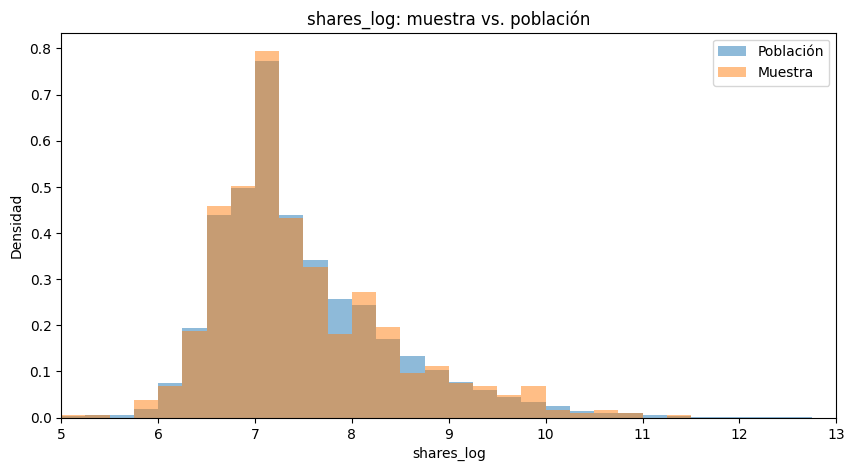

p-valor Kolmogorov-Smirnov: 0.9536


In [81]:
from scipy import stats

# Mismos intervalos para los dos histogramas, así se pueden comparar
intervalos = np.arange(0, 14, 0.25)

plt.figure(figsize=(10, 5))
plt.hist(df["shares_log"], bins=intervalos, density=True, alpha=0.5, label="Población")
plt.hist(muestra_750["shares_log"], bins=intervalos, density=True, alpha=0.5, label="Muestra")
plt.title("shares_log: muestra vs. población")
plt.xlabel("shares_log")
plt.ylabel("Densidad")
plt.legend()
plt.xlim(5, 13)
plt.show()


# Prueba de Kolmogorov-Smirnov
resultado = stats.ks_2samp(muestra_750["shares_log"], df["shares_log"])
print("p-valor Kolmogorov-Smirnov:", round(resultado.pvalue, 4))

El gráfico compara la distribución de shares_log en la muestra y en la población. Las dos formas se superponen casi perfectamente: coinciden en el centro (alrededor de 7 a 7,5), en la altura del pico y en la cola hacia la derecha. Se usó la densidad en lugar de la cantidad de artículos para poder comparar ambas distribuciones, ya que la población es mucho más grande que la muestra.

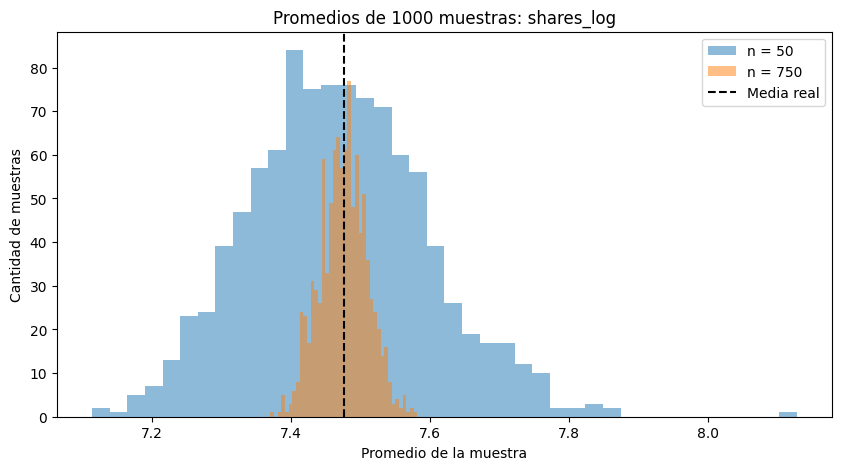

Desvío de los promedios con n = 50:  0.128
Desvío de los promedios con n = 750: 0.034
Cuántas veces más grande con n = 50: 3.79


In [80]:
np.random.seed(42)
variable = "shares_log"

medias_50 = []
medias_750 = []

# Se sacan 1000 muestras de cada tamaño y se guarda el promedio de cada una
for i in range(1000):
    medias_50.append(df[variable].sample(50).mean())
    medias_750.append(df[variable].sample(750).mean())

plt.figure(figsize=(10, 5))
plt.hist(medias_50, bins=40, alpha=0.5, label="n = 50")
plt.hist(medias_750, bins=40, alpha=0.5, label="n = 750")
plt.axvline(df[variable].mean(), color="black", linestyle="--", label="Media real")
plt.title(f"Promedios de 1000 muestras: {variable}")
plt.xlabel("Promedio de la muestra")
plt.ylabel("Cantidad de muestras")
plt.legend()
plt.show()

print("Desvío de los promedios con n = 50: ", round(np.std(medias_50), 3))
print("Desvío de los promedios con n = 750:", round(np.std(medias_750), 3))
print("Cuántas veces más grande con n = 50:", round(np.std(medias_50) / np.std(medias_750), 2))

La simulación muestra los promedios de shares_log obtenidos en 1.000 muestras de 50 artículos y en 1.000 muestras de 750 artículos. Con 50 casos, los promedios quedan muy dispersos (entre 7,15 y casi 8), por lo que el resultado depende mucho de qué artículos toquen en el sorteo. Con 750, los promedios quedan concentrados alrededor de la media real.

Si la muestra fuera de solo 50 casos, las conclusiones serían mucho menos confiables, porque el error sería casi 4 veces mayor. Además, con 50 observaciones no se podría estimar una regresión con tantas variables explicativas, ya que habría casi tantos coeficientes como datos.

## 6. MODELO ESTADÍSTICO: REGRESIÓN LINEAL

### 6.1 Preparación de las variables
### 6.2 Regresión lineal con la muestra de 750
### 6.3 Análisis de coeficientes y significatividad
### 6.4 Regresión lineal con la base completa
### 6.5 Análisis de coeficientes y significatividad
### 6.6 Comparación muestra vs. base completa
### 6.7 Comparación del R² y errores estándar

**Sección pendiente de desarrollo.**


## 7. MACHINE LEARNING

### 7.1 Preparación de los datos
### 7.2 División Train/Test
### 7.3 Modelo de Machine Learning N.º 1
### 7.4 Modelo de Machine Learning N.º 2
### 7.5 Evaluación: MAE, MSE, RMSE y R²
### 7.6 Comparación de los modelos
### 7.7 Análisis de importancia de variables
### 7.8 Overfitting y optimización

**Sección pendiente de desarrollo.**


## 8. COMPARACIÓN: ESTADÍSTICA vs. MACHINE LEARNING

### 8.1 Capacidad explicativa de la Regresión Lineal
### 8.2 Capacidad predictiva de Machine Learning
### 8.3 Interpretabilidad vs. precisión
### 8.4 Selección del modelo para producción

**Sección pendiente de desarrollo.**


## 9. CONCLUSIONES

### 9.1 Principales hallazgos
### 9.2 Validación de las hipótesis iniciales
### 9.3 Limitaciones del análisis
### 9.4 Variables adicionales que mejorarían el modelo
### 9.5 Conclusión final

**Sección pendiente de desarrollo.**
